In [1]:
import nfl_data_py as nfl
import pandas as pd

In [2]:
# Descargamos todos los draft picks de 2010 a 2022
draft = nfl.import_draft_picks(years=list(range(2010, 2023)))

# Vemos el tamaño de la tabla
print(f"Filas: {draft.shape[0]}, Columnas: {draft.shape[1]}")

# Vemos las primeras 5 filas
draft.head()

Filas: 3320, Columnas: 36


,season,round,pick,team,gsis_id,pfr_player_id,cfb_player_id,pfr_player_name,hof,position,...,pass_ints,rush_atts,rush_yards,rush_tds,receptions,rec_yards,rec_tds,def_solo_tackles,def_ints,def_sacks
8577,2010,1,1,STL,00-0027854,BradSa00,sam-bradford-1,Sam Bradford,False,QB,...,61.0,146.0,340.0,2.0,1.0,5.0,0.0,NaN,NaN,NaN
8578,2010,1,2,DET,00-0027855,SuhxNd99,ndamukong-suh-1,Ndamukong Suh,False,DT,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,392.0,1.0,71.5
8579,2010,1,3,TAM,00-0027856,McCoGe99,gerald-mccoy-1,Gerald McCoy,False,DT,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,235.0,NaN,59.5
8580,2010,1,4,WAS,00-0027857,WillTr21,trent-williams-2,Trent Williams,False,T,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,NaN,NaN
8581,2010,1,5,KAN,00-0027858,BerrEr99,eric-berry-1,Eric Berry,False,DB,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,377.0,14.0,5.5


In [3]:
# Ver todos los nombres de columnas
for col in draft.columns.tolist():
    print(col)

season
round
pick
team
gsis_id
pfr_player_id
cfb_player_id
pfr_player_name
hof
position
category
side
college
age
to
allpro
probowls
seasons_started
w_av
car_av
dr_av
games
pass_completions
pass_attempts
pass_yards
pass_tds
pass_ints
rush_atts
rush_yards
rush_tds
receptions
rec_yards
rec_tds
def_solo_tackles
def_ints
def_sacks


In [4]:
# Ver estadísticas básicas del Career AV
print("Estadísticas del Career AV:")
print(draft['car_av'].describe())

print(f"\nJugadores con car_av = 0: {(draft['car_av'] == 0).sum()}")
print(f"Jugadores con car_av nulo: {draft['car_av'].isna().sum()}")

Estadísticas del Career AV:
count    0.0
mean     NaN
std      NaN
min      NaN
25%      NaN
50%      NaN
75%      NaN
max      NaN
Name: car_av, dtype: float64

Jugadores con car_av = 0: 0
Jugadores con car_av nulo: 3320


In [5]:
# Ver cuántos valores nulos tiene cada columna
print(draft.isnull().sum())

season                 0
round                  0
pick                   0
team                   0
gsis_id               25
pfr_player_id         11
cfb_player_id        331
pfr_player_name        0
hof                    0
position               0
category               0
side                   0
college                0
age                   16
to                   239
allpro                 0
probowls               0
seasons_started        0
w_av                 239
car_av              3320
dr_av                433
games                239
pass_completions     239
pass_attempts        239
pass_yards           239
pass_tds             239
pass_ints            239
rush_atts            239
rush_yards           239
rush_tds             239
receptions           239
rec_yards            239
rec_tds              239
def_solo_tackles    1080
def_ints            2584
def_sacks           2309
dtype: int64


In [6]:
print("Estadísticas del W_AV:")
print(draft['w_av'].describe())

print(f"\nJugadores con w_av = 0: {(draft['w_av'] == 0).sum()}")
print(f"Jugadores con w_av nulo: {draft['w_av'].isna().sum()}")

# Ver los 10 jugadores con mayor w_av
print("\nTop 10 jugadores por w_av:")
draft[['pfr_player_name', 'position', 'round', 'pick', 'college', 'w_av']]\
    .sort_values('w_av', ascending=False)\
    .head(10)

Estadísticas del W_AV:
count    3081.000000
mean       17.432976
std        20.312401
min        -4.000000
25%         3.000000
50%        10.000000
75%        26.000000
max       140.000000
Name: w_av, dtype: float64

Jugadores con w_av = 0: 329
Jugadores con w_av nulo: 239

Top 10 jugadores por w_av:


,pfr_player_name,position,round,pick,college,w_av
9160,Russell Wilson,QB,3,75,Wisconsin,140.0
9132,Bobby Wagner,LB,2,47,Utah St.,129.0
9605,Aaron Donald,DT,1,13,Pittsburgh,123.0
10367,Patrick Mahomes,QB,1,10,Texas Tech,115.0
8862,Cameron Heyward,DE,1,31,Ohio St.,115.0
8832,Cam Newton,QB,1,1,Auburn,115.0
10617,Josh Allen,QB,1,7,Wyoming,111.0
10642,Lamar Jackson,QB,1,32,Louisville,110.0
8842,J.J. Watt,DE,1,11,Wisconsin,110.0
8580,Trent Williams,T,1,4,Oklahoma,109.0


In [7]:
# Descargamos los datos del combine de 2010 a 2022
combine = nfl.import_combine_data(years=list(range(2010, 2023)))

print(f"Filas: {combine.shape[0]}, Columnas: {combine.shape[1]}")
print("\nColumnas disponibles:")
for col in combine.columns.tolist():
    print(col)

Filas: 4422, Columnas: 18

Columnas disponibles:
season
draft_year
draft_team
draft_round
draft_ovr
pfr_id
cfb_id
player_name
pos
school
ht
wt
forty
bench
vertical
broad_jump
cone
shuttle


In [8]:
print("Valores nulos por prueba del Combine:")
pruebas = ['forty', 'bench', 'vertical', 'broad_jump', 'cone', 'shuttle']
for prueba in pruebas:
    nulos = combine[prueba].isna().sum()
    total = len(combine)
    pct = (nulos/total)*100
    print(f"{prueba:12} → {nulos} nulos ({pct:.1f}%)")

Valores nulos por prueba del Combine:
forty        → 438 nulos (9.9%)
bench        → 1357 nulos (30.7%)
vertical     → 921 nulos (20.8%)
broad_jump   → 978 nulos (22.1%)
cone         → 1709 nulos (38.6%)
shuttle      → 1611 nulos (36.4%)


In [9]:
df = pd.merge(
    draft[['pfr_player_name', 'pfr_player_id', 'position', 'college', 
           'season', 'round', 'pick', 'team', 'w_av', 'probowls', 
           'allpro', 'seasons_started', 'cfb_player_id']],
    combine[['pfr_id', 'forty', 'bench', 'vertical', 
             'broad_jump', 'cone', 'shuttle', 'ht', 'wt']],
    left_on='pfr_player_id',
    right_on='pfr_id',
    how='left'
)

print(f"Filas resultantes: {df.shape[0]}")
df.head()

Filas resultantes: 8130


,pfr_player_name,pfr_player_id,position,college,season,round,pick,team,w_av,probowls,...,cfb_player_id,pfr_id,forty,bench,vertical,broad_jump,cone,shuttle,ht,wt
0,Sam Bradford,BradSa00,QB,Oklahoma,2010,1,1,STL,44.0,0,...,sam-bradford-1,BradSa00,4.79,NaN,NaN,NaN,NaN,NaN,6-4,236.0
1,Ndamukong Suh,SuhxNd99,DT,Nebraska,2010,1,2,DET,100.0,5,...,ndamukong-suh-1,SuhxNd99,5.03,32.0,35.5,105.0,7.21,4.44,6-4,307.0
2,Gerald McCoy,McCoGe99,DT,Oklahoma,2010,1,3,TAM,69.0,6,...,gerald-mccoy-1,McCoGe99,5.04,23.0,30.5,114.0,7.32,4.48,6-4,295.0
3,Trent Williams,WillTr21,T,Oklahoma,2010,1,4,WAS,109.0,12,...,trent-williams-2,WillTr21,4.81,23.0,34.5,113.0,7.64,4.63,6-5,315.0
4,Eric Berry,BerrEr99,DB,Tennessee,2010,1,5,KAN,50.0,5,...,eric-berry-1,BerrEr99,4.40,19.0,43.0,130.0,6.80,4.23,6-0,211.0


In [10]:
# Verificar si hay IDs duplicados en el combine
print("IDs duplicados en combine:")
print(combine['pfr_id'].duplicated().sum())

# Verificar si hay IDs duplicados en draft
print("\nIDs duplicados en draft:")
print(draft['pfr_player_id'].duplicated().sum())

# Ver ejemplos de duplicados en combine
print("\nEjemplos de duplicados en combine:")
duplicados = combine[combine['pfr_id'].duplicated(keep=False)]
print(duplicados[['player_name', 'pfr_id', 'season', 'pos']].head(10))

IDs duplicados en combine:
441

IDs duplicados en draft:
10

Ejemplos de duplicados en combine:
            player_name pfr_id  season  pos
3259         Rahim Alem   None    2010   DE
3260  Charles Alexander   None    2010   DT
3266     Lucien Antoine   None    2010    S
3268       Alric Arnett   None    2010   WR
3273       Kevin Basped   None    2010   DE
3275    Jason Beauchamp   None    2010  ILB
3276         Chris Bell   None    2010   WR
3281        Ciron Black   None    2010   OG
3283       Nyan Boateng   None    2010   WR
3285       Brent Bowden   None    2010    P


In [11]:
# Eliminar filas sin ID en ambos datasets
draft_clean = draft.dropna(subset=['pfr_player_id'])
combine_clean = combine.dropna(subset=['pfr_id'])

# Verificar cuántos quedaron
print(f"Draft sin nulos en ID: {len(draft_clean)}")
print(f"Combine sin nulos en ID: {len(combine_clean)}")

# Repetir el merge
df = pd.merge(
    draft_clean[['pfr_player_name', 'pfr_player_id', 'position', 'college', 
                 'season', 'round', 'pick', 'team', 'w_av', 'probowls', 
                 'allpro', 'seasons_started', 'cfb_player_id']],
    combine_clean[['pfr_id', 'forty', 'bench', 'vertical', 
                   'broad_jump', 'cone', 'shuttle', 'ht', 'wt']],
    left_on='pfr_player_id',
    right_on='pfr_id',
    how='left'
)

print(f"\nFilas resultantes: {df.shape[0]}")
df.head()

Draft sin nulos en ID: 3309
Combine sin nulos en ID: 3984

Filas resultantes: 3312


,pfr_player_name,pfr_player_id,position,college,season,round,pick,team,w_av,probowls,...,cfb_player_id,pfr_id,forty,bench,vertical,broad_jump,cone,shuttle,ht,wt
0,Sam Bradford,BradSa00,QB,Oklahoma,2010,1,1,STL,44.0,0,...,sam-bradford-1,BradSa00,4.79,NaN,NaN,NaN,NaN,NaN,6-4,236.0
1,Ndamukong Suh,SuhxNd99,DT,Nebraska,2010,1,2,DET,100.0,5,...,ndamukong-suh-1,SuhxNd99,5.03,32.0,35.5,105.0,7.21,4.44,6-4,307.0
2,Gerald McCoy,McCoGe99,DT,Oklahoma,2010,1,3,TAM,69.0,6,...,gerald-mccoy-1,McCoGe99,5.04,23.0,30.5,114.0,7.32,4.48,6-4,295.0
3,Trent Williams,WillTr21,T,Oklahoma,2010,1,4,WAS,109.0,12,...,trent-williams-2,WillTr21,4.81,23.0,34.5,113.0,7.64,4.63,6-5,315.0
4,Eric Berry,BerrEr99,DB,Tennessee,2010,1,5,KAN,50.0,5,...,eric-berry-1,BerrEr99,4.40,19.0,43.0,130.0,6.80,4.23,6-0,211.0


In [12]:
# Ver cuántos jugadores tienen datos del combine y cuántos no
con_combine = df['forty'].notna().sum()
sin_combine = df['forty'].isna().sum()

print(f"Jugadores CON datos del combine: {con_combine}")
print(f"Jugadores SIN datos del combine: {sin_combine}")

# Ver un jugador conocido para confirmar que todo está bien
print("\nBuscando a Patrick Mahomes:")
print(df[df['pfr_player_name'] == 'Patrick Mahomes'][
    ['pfr_player_name', 'position', 'round', 'pick', 'w_av', 'forty', 'vertical']
])

Jugadores CON datos del combine: 2555
Jugadores SIN datos del combine: 757

Buscando a Patrick Mahomes:
      pfr_player_name position  round  pick   w_av  forty  vertical
1781  Patrick Mahomes       QB      1    10  115.0    4.8      30.0


In [13]:
# Contar jugadores por posición ordenados de mayor a menor
print("Jugadores por posición:")
print(df['position'].value_counts())

Jugadores por posición:
WR     412
DB     326
LB     305
DE     294
RB     278
DT     243
T      214
CB     210
TE     187
G      152
QB     149
S      139
OL     110
OLB     77
C       70
ILB     34
DL      31
P       24
K       23
FB      14
NT      11
LS       8
OT       1
Name: position, dtype: int64


In [14]:
# Diccionario de agrupación
posicion_map = {
    # Quarterbacks
    'QB': 'QB',
    # Running backs
    'RB': 'RB', 'FB': 'RB',
    # Receptores
    'WR': 'WR', 'TE': 'TE',
    # Línea ofensiva
    'T': 'OL', 'G': 'OL', 'C': 'OL', 'OL': 'OL', 'OT': 'OL',
    # Línea defensiva
    'DE': 'EDGE', 'OLB': 'EDGE',
    'DT': 'DL', 'NT': 'DL', 'DL': 'DL',
    # Linebackers
    'LB': 'LB', 'ILB': 'LB',
    # Secundaria
    'CB': 'CB', 'DB': 'DB', 'S': 'S',
    # Special teams - los excluimos del análisis
    'P': None, 'K': None, 'LS': None
}

# Aplicar el mapa
df['position_group'] = df['position'].map(posicion_map)

# Eliminar special teams y posiciones sin grupo
df = df[df['position_group'].notna()].copy()

# Ver resultado
print("Jugadores por grupo de posición:")
print(df['position_group'].value_counts())
print(f"\nTotal jugadores: {len(df)}")

Jugadores por grupo de posición:
OL      547
WR      412
EDGE    371
LB      339
DB      326
RB      292
DL      285
CB      210
TE      187
QB      149
S       139
Name: position_group, dtype: int64

Total jugadores: 3257


In [16]:
# Nos quedamos solo con las posiciones que vamos a analizar
posiciones_analisis = ['QB', 'RB', 'WR', 'EDGE']

df_analisis = df[df['position_group'].isin(posiciones_analisis)].copy()

print(f"Jugadores en el análisis: {len(df_analisis)}")
print("\nPor posición:")
print(df_analisis['position_group'].value_counts())

# Ver cuántos tienen w_av disponible
print("\nJugadores CON w_av por posición:")
print(df_analisis.groupby('position_group')['w_av'].apply(lambda x: x.notna().sum()))

Jugadores en el análisis: 1224

Por posición:
WR      412
EDGE    371
RB      292
QB      149
Name: position_group, dtype: int64

Jugadores CON w_av por posición:
position_group
EDGE    347
QB      123
RB      272
WR      383
Name: w_av, dtype: int64


In [17]:
print("W_AV promedio por ronda de draft:")
resultado = df_analisis.groupby('round')['w_av']\
    .agg(['mean', 'count'])\
    .round(2)
resultado.columns = ['w_av_promedio', 'jugadores']
print(resultado)

W_AV promedio por ronda de draft:
       w_av_promedio  jugadores
round                          
1              41.08        170
2              25.49        158
3              19.63        160
4              13.69        175
5              10.18        147
6               6.19        160
7               4.39        155


In [18]:
# API key de CollegeFootballData (gratuita): se lee de la variable de entorno CFBD_API_KEY
import os
API_KEY = os.environ.get("CFBD_API_KEY", "")

print("API key configurada")

API key configurada


In [20]:
# Ver qué métodos tiene PlayersApi en esta versión
metodos = [m for m in dir(stats_api) if not m.startswith('_')]
for m in metodos:
    print(m)

api_client
get_player_usage
get_player_usage_with_http_info
get_returning_production
get_returning_production_with_http_info
get_transfer_portal
get_transfer_portal_with_http_info
search_players
search_players_with_http_info


In [21]:
# Ver todas las clases disponibles en cfbd
import inspect
clases = [name for name, obj in inspect.getmembers(cfbd) if inspect.isclass(obj) and 'Api' in name]
for clase in clases:
    print(clase)

AdjustedMetricsApi
ApiAttributeError
ApiClient
ApiException
ApiKeyError
ApiResponse
ApiTypeError
ApiValueError
BettingApi
CoachesApi
ConferencesApi
DraftApi
DrivesApi
GamesApi
InfoApi
MetricsApi
OpenApiException
PlayersApi
PlaysApi
RankingsApi
RatingsApi
RecruitingApi
StatsApi
TeamsApi
VenuesApi


In [22]:
# Crear instancia de StatsApi
stats_api = cfbd.StatsApi(api_client)

# Ver métodos disponibles
metodos = [m for m in dir(stats_api) if not m.startswith('_') and 'http' not in m]
for m in metodos:
    print(m)

api_client
get_advanced_game_stats
get_advanced_season_stats
get_categories
get_game_havoc_stats
get_player_season_stats
get_team_stats


In [27]:
!pip install requests --quiet

In [28]:
import requests

# Hacer la llamada directamente a la API sin la librería cfbd
url = "https://api.collegefootballdata.com/stats/player/season"
headers = {
    "Authorization": f"Bearer {API_KEY}",
    "accept": "application/json"
}
params = {
    "year": 2016,
    "category": "passing"
}

response = requests.get(url, headers=headers, params=params)
print(f"Status code: {response.status_code}")
print(f"Respuesta: {response.text[:500]}")

Status code: 200
Respuesta: [{"season":2016,"playerId":"482594","player":"Taysom Hill","position":"QB","team":"BYU","conference":"FBS Independents","category":"passing","statType":"ATT","stat":"374"},{"season":2016,"playerId":"482594","player":"Taysom Hill","position":"QB","team":"BYU","conference":"FBS Independents","category":"passing","statType":"COMPLETIONS","stat":"222"},{"season":2016,"playerId":"482594","player":"Taysom Hill","position":"QB","team":"BYU","conference":"FBS Independents","category":"passing","statType


In [29]:
import json

# Convertir respuesta a JSON
data = response.json()

# Ver todos los tipos de stats únicos
stat_types = list(set([r['statType'] for r in data]))
stat_types.sort()

print(f"Total registros: {len(data)}")
print(f"\nTipos de stats disponibles para passing:")
for st in stat_types:
    print(f"  {st}")

Total registros: 4725

Tipos de stats disponibles para passing:
  ATT
  COMPLETIONS
  INT
  PCT
  TD
  YDS
  YPA


In [30]:
def get_college_stats(year, category):
    """
    Obtiene stats de jugadores universitarios para un año y categoría,
    y las transforma en una tabla donde cada fila es un jugador.
    """
    url = "https://api.collegefootballdata.com/stats/player/season"
    headers = {
        "Authorization": f"Bearer {API_KEY}",
        "accept": "application/json"
    }
    params = {"year": year, "category": category}
    
    response = requests.get(url, headers=headers, params=params)
    data = response.json()
    
    # Convertir a DataFrame
    df_raw = pd.DataFrame(data)
    
    # Actualmente cada stat es una fila separada
    # Necesitamos pivotear para tener una fila por jugador
    df_pivot = df_raw.pivot_table(
        index=['playerId', 'player', 'team', 'conference', 'position'],
        columns='statType',
        values='stat',
        aggfunc='first'
    ).reset_index()
    
    # Limpiar nombres de columnas
    df_pivot.columns.name = None
    
    # Añadir el año
    df_pivot['season'] = year
    
    return df_pivot

# Probar con QBs de 2016
test_qb = get_college_stats(2016, 'passing')
print(f"Filas: {test_qb.shape[0]}, Columnas: {test_qb.shape[1]}")
print("\nPrimeras filas:")
test_qb.head()

Filas: 675, Columnas: 13

Primeras filas:


,playerId,player,team,conference,position,ATT,COMPLETIONS,INT,PCT,TD,YDS,YPA,season
0,3068222,Conner Cramer,New Mexico State,Sun Belt,QB,39,17,3,0.436,2,188,4.8,2016
1,3115912,Chayce Crouch,Illinois,Big Ten,QB,32,18,1,0.563,1,249,7.8,2016
2,3115966,Wilton Speight,Michigan,Big Ten,QB,331,204,7,0.616,18,2538,7.7,2016
3,3116091,Zack Darlington,Nebraska,Big Ten,WR,6,2,0,0.333,0,14,2.3,2016
4,3116144,Clayton Thorson,Northwestern,Big Ten,QB,478,280,9,0.586,22,3182,6.7,2016


In [31]:
# Los años universitarios que necesitamos son 2009-2021
años_college = list(range(2009, 2022))
categorias = ['passing', 'rushing', 'receiving', 'defensive']

# Diccionario para guardar todos los datos
college_data = {}

for categoria in categorias:
    print(f"Descargando {categoria}...")
    dfs = []
    for año in años_college:
        df_año = get_college_stats(año, categoria)
        dfs.append(df_año)
    
    # Combinar todos los años en un solo DataFrame
    college_data[categoria] = pd.concat(dfs, ignore_index=True)
    print(f"  → {len(college_data[categoria])} registros totales")

print("\n¡Descarga completa!")

Descargando passing...
  → 7854 registros totales
Descargando rushing...
  → 24134 registros totales
Descargando receiving...
  → 30658 registros totales
Descargando defensive...


KeyError: 'stat'

In [32]:
def get_college_stats(year, category):
    """
    Obtiene stats de jugadores universitarios para un año y categoría.
    """
    url = "https://api.collegefootballdata.com/stats/player/season"
    headers = {
        "Authorization": f"Bearer {API_KEY}",
        "accept": "application/json"
    }
    params = {"year": year, "category": category}
    
    response = requests.get(url, headers=headers, params=params)
    data = response.json()
    
    # Si no hay datos devolvemos DataFrame vacío
    if not data or len(data) == 0:
        return pd.DataFrame()
    
    df_raw = pd.DataFrame(data)
    
    # Verificar que las columnas necesarias existen
    if 'statType' not in df_raw.columns or 'stat' not in df_raw.columns:
        print(f"  ⚠ Año {year} categoría {category}: columnas inesperadas {df_raw.columns.tolist()}")
        return pd.DataFrame()
    
    try:
        df_pivot = df_raw.pivot_table(
            index=['playerId', 'player', 'team', 'conference', 'position'],
            columns='statType',
            values='stat',
            aggfunc='first'
        ).reset_index()
        
        df_pivot.columns.name = None
        df_pivot['season'] = year
        return df_pivot
        
    except Exception as e:
        print(f"  ⚠ Error en año {year} categoría {category}: {e}")
        return pd.DataFrame()

# Probar que funciona
test = get_college_stats(2016, 'passing')
print(f"Test exitoso: {len(test)} jugadores")

Test exitoso: 675 jugadores


In [33]:
# Los años universitarios que necesitamos son 2009-2021
años_college = list(range(2009, 2022))
categorias = ['passing', 'rushing', 'receiving', 'defensive']

# Diccionario para guardar todos los datos
college_data = {}

for categoria in categorias:
    print(f"Descargando {categoria}...")
    dfs = []
    for año in años_college:
        df_año = get_college_stats(año, categoria)
        if len(df_año) > 0:
            dfs.append(df_año)
    
    # Combinar todos los años en un solo DataFrame
    if dfs:
        college_data[categoria] = pd.concat(dfs, ignore_index=True)
        print(f"  → {len(college_data[categoria])} registros totales")
    else:
        print(f"  → Sin datos")

print("\n¡Descarga completa!")

Descargando passing...
  → 7854 registros totales
Descargando rushing...
  → 24134 registros totales
Descargando receiving...
  → 30658 registros totales
Descargando defensive...
  → 43931 registros totales

¡Descarga completa!


In [34]:
import os

# Crear carpeta para los datos crudos
os.makedirs('data_raw', exist_ok=True)

# Guardar draft + combine
df_analisis.to_csv('data_raw/draft_combine.csv', index=False)
print(f"✅ draft_combine.csv guardado — {len(df_analisis)} filas")

# Guardar cada categoría de college
for categoria, df in college_data.items():
    filename = f'data_raw/college_{categoria}.csv'
    df.to_csv(filename, index=False)
    print(f"✅ college_{categoria}.csv guardado — {len(df)} filas")

print("\n¡Todo guardado en la carpeta data_raw!")

✅ draft_combine.csv guardado — 1224 filas
✅ college_passing.csv guardado — 7854 filas
✅ college_rushing.csv guardado — 24134 filas
✅ college_receiving.csv guardado — 30658 filas
✅ college_defensive.csv guardado — 43931 filas

¡Todo guardado en la carpeta data_raw!


In [35]:
for categoria, df in college_data.items():
    cols = [c for c in df.columns if c not in ['playerId', 'player', 'team', 'conference', 'position', 'season']]
    print(f"\n{categoria.upper()}:")
    print(f"  Columnas de stats: {cols}")


PASSING:
  Columnas de stats: ['ATT', 'COMPLETIONS', 'INT', 'PCT', 'TD', 'YDS', 'YPA']

RUSHING:
  Columnas de stats: ['CAR', 'LONG', 'TD', 'YDS', 'YPC']

RECEIVING:
  Columnas de stats: ['LONG', 'REC', 'TD', 'YDS', 'YPR']

DEFENSIVE:
  Columnas de stats: ['PD', 'QB HUR', 'SACKS', 'SOLO', 'TD', 'TFL', 'TOT']


In [36]:
# Verificar cuántos jugadores de df_analisis tienen cfb_player_id
con_id = df_analisis['cfb_player_id'].notna().sum()
sin_id = df_analisis['cfb_player_id'].isna().sum()

print(f"Jugadores CON cfb_player_id: {con_id}")
print(f"Jugadores SIN cfb_player_id: {sin_id}")

# Ver cómo se ve el cfb_player_id
print("\nEjemplos de cfb_player_id:")
print(df_analisis[df_analisis['cfb_player_id'].notna()]['cfb_player_id'].head(10).tolist())

# Ver cómo se ve el playerId en college_data
print("\nEjemplos de playerId en college passing:")
print(college_data['passing']['playerId'].head(10).tolist())


Jugadores CON cfb_player_id: 1135
Jugadores SIN cfb_player_id: 89

Ejemplos de cfb_player_id:
['sam-bradford-1', 'cj-spiller-1', 'ryan-mathews-1', 'brandon-graham-1', 'jason-pierre-paul-1', 'derrick-morgan-1', 'demaryius-thomas-1', 'dez-bryant-1', 'tim-tebow-1', 'jared-odrick-1']

Ejemplos de playerId en college passing:
['132870', '136470', '160044', '160307', '160603', '161504', '162068', '162666', '168823', '169067']


In [37]:
# CFBD tiene su propio endpoint de draft picks
draft_api = cfbd.DraftApi(api_client3)

# Ver métodos disponibles
metodos = [m for m in dir(draft_api) if not m.startswith('_') and 'http' not in m]
print("Métodos disponibles en DraftApi:")
for m in metodos:
    print(f"  {m}")

Métodos disponibles en DraftApi:
  api_client
  get_draft_picks
  get_draft_positions
  get_draft_teams


In [38]:
# Pedir los draft picks de 2017 como prueba
test_draft = draft_api.get_draft_picks(year=2017)

print(f"Registros obtenidos: {len(test_draft)}")
print(f"\nPrimer registro:")
print(test_draft[0])

UnauthorizedException: (401)
Reason: Unauthorized
HTTP response headers: HTTPHeaderDict({'Date': 'Wed, 13 May 2026 16:16:09 GMT', 'Content-Type': 'application/json; charset=utf-8', 'Content-Length': '255', 'Connection': 'keep-alive', 'Server': 'cloudflare', 'Nel': '{"report_to":"cf-nel","success_fraction":0.0,"max_age":604800}', 'Cross-Origin-Opener-Policy': 'same-origin', 'Cross-Origin-Resource-Policy': 'same-origin', 'Origin-Agent-Cluster': '?1', 'Referrer-Policy': 'no-referrer', 'Strict-Transport-Security': 'max-age=31536000; includeSubDomains', 'X-Content-Type-Options': 'nosniff', 'X-DNS-Prefetch-Control': 'off', 'X-Download-Options': 'noopen', 'X-Frame-Options': 'SAMEORIGIN', 'X-Permitted-Cross-Domain-Policies': 'none', 'X-XSS-Protection': '0', 'Access-Control-Allow-Origin': '*', 'ETag': 'W/"ff-gnUOGgxq5fP+briqpVd9GdbKyP4"', 'cf-cache-status': 'DYNAMIC', 'Report-To': '{"group":"cf-nel","max_age":604800,"endpoints":[{"url":"https://a.nel.cloudflare.com/report/v4?s=V5a6FwdWXAGyH%2Fp

In [39]:
def get_cfbd_draft_picks(year):
    url = "https://api.collegefootballdata.com/draft/picks"
    headers = {
        "Authorization": f"Bearer {API_KEY}",
        "accept": "application/json"
    }
    params = {"year": year}
    
    response = requests.get(url, headers=headers, params=params)
    data = response.json()
    return data

# Probar con 2017
test = get_cfbd_draft_picks(2017)
print(f"Picks obtenidos: {len(test)}")
print(f"\nPrimer registro:")
print(test[0])

Picks obtenidos: 253

Primer registro:
{'collegeAthleteId': 3122132, 'nflAthleteId': 51534, 'collegeId': 245, 'collegeTeam': 'Texas A&M', 'collegeConference': 'SEC', 'nflTeamId': 5, 'nflTeam': 'Cleveland', 'year': 2017, 'overall': 1, 'round': 1, 'pick': 1, 'name': 'Myles Garrett', 'position': 'Defensive End', 'height': 77, 'weight': 272, 'preDraftRanking': 1, 'preDraftPositionRanking': 1, 'preDraftGrade': 95, 'hometownInfo': {'city': 'Arlington', 'state': 'TX', 'country': 'USA', 'latitude': '32.701938999999996', 'longitude': '-97.10562379033699', 'countyFips': '48439'}}


In [40]:
# Descargar picks de todos los años
print("Descargando draft picks de CFBD...")
all_picks = []

for year in range(2010, 2023):
    picks = get_cfbd_draft_picks(year)
    all_picks.extend(picks)
    print(f"  {year}: {len(picks)} picks")

# Convertir a DataFrame
df_cfbd_draft = pd.DataFrame(all_picks)

print(f"\nTotal picks: {len(df_cfbd_draft)}")
print(f"\nColumnas: {df_cfbd_draft.columns.tolist()}")

Descargando draft picks de CFBD...
  2010: 255 picks
  2011: 254 picks
  2012: 253 picks
  2013: 254 picks
  2014: 256 picks
  2015: 256 picks
  2016: 253 picks
  2017: 253 picks
  2018: 256 picks
  2019: 254 picks
  2020: 255 picks
  2021: 259 picks
  2022: 262 picks

Total picks: 3320

Columnas: ['collegeAthleteId', 'nflAthleteId', 'collegeId', 'collegeTeam', 'collegeConference', 'nflTeamId', 'nflTeam', 'year', 'overall', 'round', 'pick', 'name', 'position', 'height', 'weight', 'preDraftRanking', 'preDraftPositionRanking', 'preDraftGrade', 'hometownInfo']


In [41]:
# La tabla puente conecta:
# nflverse: pfr_player_name + round + pick + season
# CFBD: collegeAthleteId + overall + round + year

# Cruzamos por round, pick y año del draft
df_bridge = pd.merge(
    df_analisis,
    df_cfbd_draft[['collegeAthleteId', 'overall', 'round', 'pick', 'year', 'preDraftGrade', 'preDraftRanking']],
    left_on=['round', 'pick', 'season'],
    right_on=['round', 'pick', 'year'],
    how='left'
)

print(f"Jugadores totales: {len(df_bridge)}")
print(f"Jugadores con collegeAthleteId: {df_bridge['collegeAthleteId'].notna().sum()}")
print(f"Jugadores sin collegeAthleteId: {df_bridge['collegeAthleteId'].isna().sum()}")

# Verificar con Mahomes
print("\nMahomes:")
print(df_bridge[df_bridge['pfr_player_name'] == 'Patrick Mahomes'][
    ['pfr_player_name', 'round', 'pick', 'season', 'collegeAthleteId', 'w_av']
])

Jugadores totales: 1224
Jugadores con collegeAthleteId: 171
Jugadores sin collegeAthleteId: 1053

Mahomes:
     pfr_player_name  round  pick  season  collegeAthleteId   w_av
674  Patrick Mahomes      1    10    2017         3139477.0  115.0


In [42]:
# Verificar que los tipos de datos son compatibles
print("Tipos de datos en df_analisis:")
print(df_analisis[['round', 'pick', 'season']].dtypes)

print("\nTipos de datos en df_cfbd_draft:")
print(df_cfbd_draft[['round', 'pick', 'year']].dtypes)

# Ver un ejemplo concreto — buscar el pick 10 ronda 1 de 2017 en cfbd
print("\nPick 10 ronda 1 año 2017 en df_cfbd_draft:")
print(df_cfbd_draft[
    (df_cfbd_draft['round'] == 1) & 
    (df_cfbd_draft['pick'] == 10) & 
    (df_cfbd_draft['year'] == 2017)
][['name', 'round', 'pick', 'year', 'collegeAthleteId']])

# Ver el mismo en df_analisis
print("\nPick 10 ronda 1 año 2017 en df_analisis:")
print(df_analisis[
    (df_analisis['round'] == 1) & 
    (df_analisis['pick'] == 10) & 
    (df_analisis['season'] == 2017)
][['pfr_player_name', 'round', 'pick', 'season']])


Tipos de datos en df_analisis:
round     int32
pick      int32
season    int32
dtype: object

Tipos de datos en df_cfbd_draft:
round    int64
pick     int64
year     int64
dtype: object

Pick 10 ronda 1 año 2017 en df_cfbd_draft:
                 name  round  pick  year  collegeAthleteId
1790  Patrick Mahomes      1    10  2017         3139477.0

Pick 10 ronda 1 año 2017 en df_analisis:
      pfr_player_name  round  pick  season
1781  Patrick Mahomes      1    10    2017


In [43]:
# Convertir todo a int64 para que sean compatibles
df_analisis['round'] = df_analisis['round'].astype('int64')
df_analisis['pick'] = df_analisis['pick'].astype('int64')
df_analisis['season'] = df_analisis['season'].astype('int64')

# Repetir el merge
df_bridge = pd.merge(
    df_analisis,
    df_cfbd_draft[['collegeAthleteId', 'overall', 'round', 'pick', 'year', 
                   'preDraftGrade', 'preDraftRanking']],
    left_on=['round', 'pick', 'season'],
    right_on=['round', 'pick', 'year'],
    how='left'
)

print(f"Jugadores totales: {len(df_bridge)}")
print(f"Jugadores con collegeAthleteId: {df_bridge['collegeAthleteId'].notna().sum()}")
print(f"Jugadores sin collegeAthleteId: {df_bridge['collegeAthleteId'].isna().sum()}")

Jugadores totales: 1224
Jugadores con collegeAthleteId: 171
Jugadores sin collegeAthleteId: 1053


In [44]:
# Verificar si hay picks duplicados en df_cfbd_draft
duplicados_cfbd = df_cfbd_draft.duplicated(subset=['round', 'pick', 'year']).sum()
print(f"Picks duplicados en df_cfbd_draft: {duplicados_cfbd}")

# Verificar si hay picks duplicados en df_analisis
duplicados_analisis = df_analisis.duplicated(subset=['round', 'pick', 'season']).sum()
print(f"Picks duplicados en df_analisis: {duplicados_analisis}")

# Ver cuántos picks de df_analisis SÍ existen en df_cfbd_draft
merged_test = pd.merge(
    df_analisis[['pfr_player_name', 'round', 'pick', 'season']],
    df_cfbd_draft[['name', 'round', 'pick', 'year']],
    left_on=['round', 'pick', 'season'],
    right_on=['round', 'pick', 'year'],
    how='inner'
)
print(f"\nJugadores que cruzan en inner join: {len(merged_test)}")
print("\nEjemplos:")
print(merged_test.head(10))

Picks duplicados en df_cfbd_draft: 0
Picks duplicados en df_analisis: 0

Jugadores que cruzan en inner join: 171

Ejemplos:
     pfr_player_name  round  pick  season               name  year
0       Sam Bradford      1     1    2010       Sam Bradford  2010
1       C.J. Spiller      1     9    2010       C.J. Spiller  2010
2       Ryan Mathews      1    12    2010       Ryan Mathews  2010
3     Brandon Graham      1    13    2010     Brandon Graham  2010
4  Jason Pierre-Paul      1    15    2010  Jason Pierre-Paul  2010
5     Derrick Morgan      1    16    2010     Derrick Morgan  2010
6   Demaryius Thomas      1    22    2010   Demaryius Thomas  2010
7         Dez Bryant      1    24    2010         Dez Bryant  2010
8          Tim Tebow      1    25    2010          Tim Tebow  2010
9       Jared Odrick      1    28    2010       Jared Odrick  2010


In [45]:
# Ver cuántos picks cruzan por ronda
print("Picks que cruzan exitosamente por ronda:")
print(merged_test.groupby('round').size())

print("\nPicks en df_analisis por ronda:")
print(df_analisis.groupby('round').size())

print("\nPicks en df_cfbd_draft por ronda:")
print(df_cfbd_draft.groupby('round').size())

Picks que cruzan exitosamente por ronda:
round
1    170
2      1
dtype: int64

Picks en df_analisis por ronda:
round
1    170
2    159
3    165
4    184
5    158
6    184
7    204
dtype: int64

Picks en df_cfbd_draft por ronda:
round
1    415
2    413
3    481
4    488
5    475
6    517
7    531
dtype: int64


In [46]:
# Usar df completo, no df_analisis que ya está filtrado por posición
df_bridge = pd.merge(
    df[['pfr_player_name', 'pfr_player_id', 'position', 'position_group',
        'college', 'season', 'round', 'pick', 'team', 'w_av', 
        'probowls', 'allpro', 'seasons_started', 'cfb_player_id',
        'forty', 'bench', 'vertical', 'broad_jump', 'cone', 'shuttle', 
        'ht', 'wt']],
    df_cfbd_draft[['collegeAthleteId', 'round', 'pick', 'year',
                   'preDraftGrade', 'preDraftRanking']],
    left_on=['round', 'pick', 'season'],
    right_on=['round', 'pick', 'year'],
    how='left'
)

print(f"Jugadores totales: {len(df_bridge)}")
print(f"Jugadores con collegeAthleteId: {df_bridge['collegeAthleteId'].notna().sum()}")

# Verificar por ronda
print("\nCruce exitoso por ronda:")
print(df_bridge.groupby('round')['collegeAthleteId'].notna().sum())

KeyError: "['pfr_player_name', 'pfr_player_id', 'position_group', 'college', 'round', 'pick', 'w_av', 'probowls', 'allpro', 'seasons_started', 'cfb_player_id', 'forty', 'bench', 'vertical', 'broad_jump', 'cone', 'shuttle', 'ht', 'wt'] not in index"

In [47]:
# Reconstruir el merge original draft + combine con TODOS los jugadores
df_completo = pd.merge(
    draft_clean[['pfr_player_name', 'pfr_player_id', 'position', 'college', 
                 'season', 'round', 'pick', 'team', 'w_av', 'probowls', 
                 'allpro', 'seasons_started', 'cfb_player_id']],
    combine_clean[['pfr_id', 'forty', 'bench', 'vertical', 
                   'broad_jump', 'cone', 'shuttle', 'ht', 'wt']],
    left_on='pfr_player_id',
    right_on='pfr_id',
    how='left'
)

# Añadir position_group
df_completo['position_group'] = df_completo['position'].map(posicion_map)

# Convertir tipos para el merge
df_completo['round'] = df_completo['round'].astype('int64')
df_completo['pick'] = df_completo['pick'].astype('int64')
df_completo['season'] = df_completo['season'].astype('int64')

print(f"df_completo: {len(df_completo)} jugadores")
print(f"Columnas: {df_completo.columns.tolist()}")

df_completo: 3312 jugadores
Columnas: ['pfr_player_name', 'pfr_player_id', 'position', 'college', 'season', 'round', 'pick', 'team', 'w_av', 'probowls', 'allpro', 'seasons_started', 'cfb_player_id', 'pfr_id', 'forty', 'bench', 'vertical', 'broad_jump', 'cone', 'shuttle', 'ht', 'wt', 'position_group']


In [50]:
df_bridge = pd.merge(
    df_completo,
    df_cfbd_draft[['collegeAthleteId', 'round', 'pick', 'year',
                   'preDraftGrade', 'preDraftRanking']],
    left_on=['round', 'pick', 'season'],
    right_on=['round', 'pick', 'year'],
    how='left'
)

print(f"Jugadores totales: {len(df_bridge)}")
print(f"Jugadores con collegeAthleteId: {df_bridge['collegeAthleteId'].notna().sum()}")
print(f"Jugadores sin collegeAthleteId: {df_bridge['collegeAthleteId'].isna().sum()}")

print("\nCruce exitoso por ronda:")
print(df_bridge.groupby('round')['collegeAthleteId'].apply(lambda x: x.notna().sum()))

Jugadores totales: 3312
Jugadores con collegeAthleteId: 416
Jugadores sin collegeAthleteId: 2896

Cruce exitoso por ronda:
round
1    415
2      1
3      0
4      0
5      0
6      0
7      0
Name: collegeAthleteId, dtype: int64


In [51]:
df_cfbd_draft.to_csv('data_raw/cfbd_draft_picks.csv', index=False)
print("Guardado!")

Guardado!


In [52]:
print(df_completo.shape)
print(df_cfbd_draft.shape)

(3312, 23)
(3320, 19)


In [53]:
df_bridge = pd.merge(
    df_completo,
    df_cfbd_draft[['collegeAthleteId', 'overall', 'year',
                   'preDraftGrade', 'preDraftRanking']],
    left_on=['pick', 'season'],
    right_on=['overall', 'year'],
    how='left'
)

print(f"Jugadores totales: {len(df_bridge)}")
print(f"Jugadores con collegeAthleteId: {df_bridge['collegeAthleteId'].notna().sum()}")
print(f"Jugadores sin collegeAthleteId: {df_bridge['collegeAthleteId'].isna().sum()}")

print("\nCruce exitoso por ronda:")
print(df_bridge.groupby('round')['collegeAthleteId'].apply(lambda x: x.notna().sum()))

Jugadores totales: 3312
Jugadores con collegeAthleteId: 3263
Jugadores sin collegeAthleteId: 49

Cruce exitoso por ronda:
round
1    415
2    409
3    479
4    485
5    469
6    498
7    508
Name: collegeAthleteId, dtype: int64


In [54]:
df_bridge.to_csv('data_raw/df_bridge.csv', index=False)
print(f"Guardado! {len(df_bridge)} jugadores")

Guardado! 3312 jugadores


In [55]:
# Ver ejemplos de IDs negativos
print("Ejemplos de collegeAthleteId negativos:")
print(df_bridge[df_bridge['collegeAthleteId'] < 0][
    ['pfr_player_name', 'position', 'season', 'round', 'pick', 'collegeAthleteId']
].head(10))

# Cuántos son negativos
negativos = (df_bridge['collegeAthleteId'] < 0).sum()
print(f"\nTotal IDs negativos: {negativos}")

# Ver si esos IDs existen en college_data
id_negativo_ejemplo = df_bridge[df_bridge['collegeAthleteId'] < 0]['collegeAthleteId'].iloc[0]
print(f"\nBuscando ID {id_negativo_ejemplo} en college passing:")
print(college_data['passing'][college_data['passing']['playerId'] == str(int(id_negativo_ejemplo))].head())

Ejemplos de collegeAthleteId negativos:
     pfr_player_name position  season  round  pick  collegeAthleteId
3     Trent Williams        T    2010      1     4        -1027647.0
5      Russell Okung        T    2010      1     6        -1028035.0
17  Maurkice Pouncey        C    2010      1    18        -1009969.0
22      Bryan Bulaga        T    2010      1    23        -1014435.0
25      Dan Williams       DT    2010      1    26        -1034574.0
27      Jared Odrick       DE    2010      1    28        -1029261.0
32    Rodger Saffold        T    2010      2    33        -1014116.0
39          Koa Misi       LB    2010      2    40        -1040187.0
42     Sergio Kindle       LB    2010      2    43        -1034908.0
43    Lamarr Houston       DE    2010      2    44        -1034906.0

Total IDs negativos: 466

Buscando ID -1027647.0 en college passing:
Empty DataFrame
Columns: [playerId, player, team, conference, position, ATT, COMPLETIONS, INT, PCT, TD, YDS, YPA, season]
Index: []

In [56]:
# Reemplazar IDs negativos con NaN
df_bridge.loc[df_bridge['collegeAthleteId'] < 0, 'collegeAthleteId'] = None

# Verificar resultado
validos = df_bridge['collegeAthleteId'].notna().sum()
invalidos = df_bridge['collegeAthleteId'].isna().sum()

print(f"Jugadores con ID válido: {validos}")
print(f"Jugadores sin ID válido: {invalidos}")
print(f"Total: {len(df_bridge)}")

Jugadores con ID válido: 2797
Jugadores sin ID válido: 515
Total: 3312


In [57]:
# En college_data el playerId es string, necesitamos que collegeAthleteId también lo sea
df_bridge['collegeAthleteId_str'] = df_bridge['collegeAthleteId'].apply(
    lambda x: str(int(x)) if pd.notna(x) else None
)

# Verificar que coinciden con los IDs de college_data
ejemplo_id = df_bridge[df_bridge['pfr_player_name'] == 'Patrick Mahomes']['collegeAthleteId_str'].iloc[0]
print(f"ID de Mahomes: {ejemplo_id}")

# Buscar a Mahomes en college passing
print("\nMahomes en college passing:")
print(college_data['passing'][college_data['passing']['playerId'] == ejemplo_id][
    ['player', 'season', 'YDS', 'TD', 'INT', 'PCT']
])

ID de Mahomes: 3139477

Mahomes en college passing:
               player  season   YDS  TD INT    PCT
2643  Patrick Mahomes    2014  1547  16   4  0.568
3344  Patrick Mahomes    2015  4653  36  15  0.635
4002  Patrick Mahomes    2016  5052  41  10  0.657


In [58]:
def get_player_college_stats(athlete_id):
    """
    Para un jugador dado, busca todas sus temporadas universitarias
    en todas las categorías y las agrupa por temporada.
    """
    if athlete_id is None:
        return []
    
    # Diccionario para agrupar stats por temporada
    temporadas = {}
    
    # Buscar en cada categoría
    for categoria, df_cat in college_data.items():
        registros = df_cat[df_cat['playerId'] == athlete_id]
        
        for _, row in registros.iterrows():
            season = int(row['season'])
            
            # Si esta temporada no existe aún, crearla
            if season not in temporadas:
                temporadas[season] = {'temporada': season}
            
            # Agregar las stats de esta categoría
            # Solo incluir columnas que no son metadata
            stats_cols = [c for c in df_cat.columns 
                         if c not in ['playerId', 'player', 'team', 
                                     'conference', 'position', 'season']]
            
            stats = {}
            for col in stats_cols:
                if pd.notna(row[col]):
                    stats[col] = row[col]
            
            if stats:
                temporadas[season][categoria] = stats
    
    # Convertir a lista ordenada por temporada
    return sorted(temporadas.values(), key=lambda x: x['temporada'])

# Probar con Mahomes
mahomes_id = df_bridge[df_bridge['pfr_player_name'] == 'Patrick Mahomes']['collegeAthleteId_str'].iloc[0]
mahomes_stats = get_player_college_stats(mahomes_id)

print("College stats de Mahomes:")
for temporada in mahomes_stats:
    print(f"\n  {temporada}")

College stats de Mahomes:

  {'temporada': 2014, 'passing': {'ATT': '185', 'COMPLETIONS': '105', 'INT': '4', 'PCT': '0.568', 'TD': '16', 'YDS': '1547', 'YPA': '8.4'}, 'rushing': {'CAR': '46', 'LONG': '14', 'TD': '0', 'YDS': '104', 'YPC': '2.3'}}

  {'temporada': 2015, 'passing': {'ATT': '573', 'COMPLETIONS': '364', 'INT': '15', 'PCT': '0.635', 'TD': '36', 'YDS': '4653', 'YPA': '8.1'}, 'rushing': {'CAR': '131', 'LONG': '25', 'TD': '10', 'YDS': '456', 'YPC': '3.5'}, 'receiving': {'LONG': '3', 'REC': '1', 'TD': '0', 'YDS': '3', 'YPR': '3.0'}}

  {'temporada': 2016, 'passing': {'ATT': '591', 'COMPLETIONS': '388', 'INT': '10', 'PCT': '0.657', 'TD': '41', 'YDS': '5052', 'YPA': '8.5'}, 'rushing': {'CAR': '131', 'LONG': '32', 'TD': '12', 'YDS': '285', 'YPC': '2.2'}}


In [59]:
def get_player_college_stats(athlete_id):
    if athlete_id is None:
        return []
    
    temporadas = {}
    
    for categoria, df_cat in college_data.items():
        registros = df_cat[df_cat['playerId'] == athlete_id]
        
        for _, row in registros.iterrows():
            season = int(row['season'])
            
            if season not in temporadas:
                temporadas[season] = {'temporada': season}
            
            stats_cols = [c for c in df_cat.columns 
                         if c not in ['playerId', 'player', 'team', 
                                     'conference', 'position', 'season']]
            
            stats = {}
            for col in stats_cols:
                if pd.notna(row[col]):
                    # Convertir a número
                    try:
                        val = float(row[col])
                        # Si es entero lo guardamos como int
                        stats[col] = int(val) if val == int(val) else round(val, 3)
                    except:
                        stats[col] = row[col]
            
            if stats:
                temporadas[season][categoria] = stats
    
    return sorted(temporadas.values(), key=lambda x: x['temporada'])

# Probar de nuevo con Mahomes
mahomes_stats = get_player_college_stats(mahomes_id)
print("College stats de Mahomes con tipos corregidos:")
for temporada in mahomes_stats:
    print(f"\n  {temporada}")

College stats de Mahomes con tipos corregidos:

  {'temporada': 2014, 'passing': {'ATT': 185, 'COMPLETIONS': 105, 'INT': 4, 'PCT': 0.568, 'TD': 16, 'YDS': 1547, 'YPA': 8.4}, 'rushing': {'CAR': 46, 'LONG': 14, 'TD': 0, 'YDS': 104, 'YPC': 2.3}}

  {'temporada': 2015, 'passing': {'ATT': 573, 'COMPLETIONS': 364, 'INT': 15, 'PCT': 0.635, 'TD': 36, 'YDS': 4653, 'YPA': 8.1}, 'rushing': {'CAR': 131, 'LONG': 25, 'TD': 10, 'YDS': 456, 'YPC': 3.5}, 'receiving': {'LONG': 3, 'REC': 1, 'TD': 0, 'YDS': 3, 'YPR': 3}}

  {'temporada': 2016, 'passing': {'ATT': 591, 'COMPLETIONS': 388, 'INT': 10, 'PCT': 0.657, 'TD': 41, 'YDS': 5052, 'YPA': 8.5}, 'rushing': {'CAR': 131, 'LONG': 32, 'TD': 12, 'YDS': 285, 'YPC': 2.2}}


In [60]:
def build_player_document(row):
    """
    Construye el documento MongoDB completo para un jugador.
    """
    # Información básica
    doc = {
        'nombre': row['pfr_player_name'],
        'posicion': row['position'],
        'posicion_grupo': row['position_group'],
        'universidad': row['college'],
        
        # Información del draft
        'draft': {
            'temporada': int(row['season']),
            'ronda': int(row['round']),
            'pick': int(row['pick']),
            'equipo': row['team']
        },
        
        # Métricas de éxito en NFL
        'nfl_career': {
            'w_av': float(row['w_av']) if pd.notna(row['w_av']) else None,
            'probowls': int(row['probowls']) if pd.notna(row['probowls']) else 0,
            'allpro': int(row['allpro']) if pd.notna(row['allpro']) else 0,
            'seasons_started': int(row['seasons_started']) if pd.notna(row['seasons_started']) else 0
        },
        
        # Datos del combine
        'combine': {
            'cuarenta': float(row['forty']) if pd.notna(row['forty']) else None,
            'bench': int(row['bench']) if pd.notna(row['bench']) else None,
            'vertical': float(row['vertical']) if pd.notna(row['vertical']) else None,
            'broad_jump': int(row['broad_jump']) if pd.notna(row['broad_jump']) else None,
            'cone': float(row['cone']) if pd.notna(row['cone']) else None,
            'shuttle': float(row['shuttle']) if pd.notna(row['shuttle']) else None,
            'altura': float(row['ht']) if pd.notna(row['ht']) else None,
            'peso': float(row['wt']) if pd.notna(row['wt']) else None
        },
        
        # Stats universitarias — array de temporadas
        'college_stats': get_player_college_stats(row['collegeAthleteId_str'])
    }
    
    # Añadir preDraftGrade si existe
    if pd.notna(row.get('preDraftGrade')):
        doc['draft']['pre_draft_grade'] = float(row['preDraftGrade'])
    if pd.notna(row.get('preDraftRanking')):
        doc['draft']['pre_draft_ranking'] = int(row['preDraftRanking'])
    
    return doc

# Probar con Mahomes
mahomes_row = df_bridge[df_bridge['pfr_player_name'] == 'Patrick Mahomes'].iloc[0]
mahomes_doc = build_player_document(mahomes_row)

import json
print(json.dumps(mahomes_doc, indent=2))

ValueError: could not convert string to float: '6-2'

In [61]:
def convert_height(ht_str):
    """Convierte altura de formato '6-2' a centímetros"""
    try:
        pies, pulgadas = str(ht_str).split('-')
        total_pulgadas = int(pies) * 12 + int(pulgadas)
        return round(total_pulgadas * 2.54, 1)
    except:
        return None

def build_player_document(row):
    doc = {
        'nombre': row['pfr_player_name'],
        'posicion': row['position'],
        'posicion_grupo': row['position_group'],
        'universidad': row['college'],
        
        'draft': {
            'temporada': int(row['season']),
            'ronda': int(row['round']),
            'pick': int(row['pick']),
            'equipo': row['team']
        },
        
        'nfl_career': {
            'w_av': float(row['w_av']) if pd.notna(row['w_av']) else None,
            'probowls': int(row['probowls']) if pd.notna(row['probowls']) else 0,
            'allpro': int(row['allpro']) if pd.notna(row['allpro']) else 0,
            'seasons_started': int(row['seasons_started']) if pd.notna(row['seasons_started']) else 0
        },
        
        'combine': {
            'cuarenta': float(row['forty']) if pd.notna(row['forty']) else None,
            'bench': int(row['bench']) if pd.notna(row['bench']) else None,
            'vertical': float(row['vertical']) if pd.notna(row['vertical']) else None,
            'broad_jump': int(row['broad_jump']) if pd.notna(row['broad_jump']) else None,
            'cone': float(row['cone']) if pd.notna(row['cone']) else None,
            'shuttle': float(row['shuttle']) if pd.notna(row['shuttle']) else None,
            'altura_cm': convert_height(row['ht']) if pd.notna(row['ht']) else None,
            'peso_kg': round(float(row['wt']) * 0.453592, 1) if pd.notna(row['wt']) else None
        },
        
        'college_stats': get_player_college_stats(row['collegeAthleteId_str'])
    }
    
    if pd.notna(row.get('preDraftGrade')):
        doc['draft']['pre_draft_grade'] = float(row['preDraftGrade'])
    if pd.notna(row.get('preDraftRanking')):
        doc['draft']['pre_draft_ranking'] = int(row['preDraftRanking'])
    
    return doc

# Probar con Mahomes
mahomes_row = df_bridge[df_bridge['pfr_player_name'] == 'Patrick Mahomes'].iloc[0]
mahomes_doc = build_player_document(mahomes_row)

import json
print(json.dumps(mahomes_doc, indent=2))

{
  "nombre": "Patrick Mahomes",
  "posicion": "QB",
  "posicion_grupo": "QB",
  "universidad": "Texas Tech",
  "draft": {
    "temporada": 2017,
    "ronda": 1,
    "pick": 10,
    "equipo": "KAN",
    "pre_draft_grade": 85.0,
    "pre_draft_ranking": 44
  },
  "nfl_career": {
    "w_av": 115.0,
    "probowls": 6,
    "allpro": 2,
    "seasons_started": 8
  },
  "combine": {
    "cuarenta": 4.8,
    "bench": null,
    "vertical": 30.0,
    "broad_jump": 114,
    "cone": 6.88,
    "shuttle": 4.08,
    "altura_cm": 188.0,
    "peso_kg": 102.1
  },
  "college_stats": [
    {
      "temporada": 2014,
      "passing": {
        "ATT": 185,
        "COMPLETIONS": 105,
        "INT": 4,
        "PCT": 0.568,
        "TD": 16,
        "YDS": 1547,
        "YPA": 8.4
      },
      "rushing": {
        "CAR": 46,
        "LONG": 14,
        "TD": 0,
        "YDS": 104,
        "YPC": 2.3
      }
    },
    {
      "temporada": 2015,
      "passing": {
        "ATT": 573,
        "COMPLETIONS":

In [62]:
print("Construyendo documentos para todos los jugadores...")

documentos = []
errores = 0

for _, row in df_bridge.iterrows():
    try:
        doc = build_player_document(row)
        documentos.append(doc)
    except Exception as e:
        errores += 1

print(f"Documentos construidos: {len(documentos)}")
print(f"Errores: {errores}")
print(f"\nEjemplo de documento aleatorio:")

import random
ejemplo = random.choice(documentos)
print(f"Jugador: {ejemplo['nombre']}")
print(f"Posición: {ejemplo['posicion']}")
print(f"Temporadas en college: {len(ejemplo['college_stats'])}")

Construyendo documentos para todos los jugadores...
Documentos construidos: 3312
Errores: 0

Ejemplo de documento aleatorio:
Jugador: Chris Givens
Posición: WR
Temporadas en college: 3


In [63]:
import json

# Guardar todos los documentos en un archivo JSON
with open('data_raw/nfl_players.json', 'w', encoding='utf-8') as f:
    json.dump(documentos, f, indent=2, ensure_ascii=False)

print(f"Archivo guardado: nfl_players.json")
print(f"Documentos: {len(documentos)}")

# Verificar el tamaño del archivo
import os
size = os.path.getsize('data_raw/nfl_players.json')
print(f"Tamaño: {size / (1024*1024):.2f} MB")

Archivo guardado: nfl_players.json
Documentos: 3312
Tamaño: 3.66 MB


In [64]:
# Descargar draft picks del año 2000
draft_2000 = nfl.import_draft_picks(years=[2000])

# Buscar a Brady
brady_draft = draft_2000[draft_2000['pfr_player_name'] == 'Tom Brady']
print("Datos de draft de Brady:")
print(brady_draft[['pfr_player_name', 'position', 'season', 'round', 'pick', 
                    'team', 'w_av', 'probowls', 'allpro', 'seasons_started']].to_string())

Datos de draft de Brady:
     pfr_player_name position  season  round  pick team   w_av  probowls  allpro  seasons_started
6224       Tom Brady       QB    2000      6   199  NWE  184.0        15       3               21


In [65]:
# Descargar combine del año 2000
combine_2000 = nfl.import_combine_data(years=[2000])

# Buscar a Brady
brady_combine = combine_2000[combine_2000['player_name'] == 'Tom Brady']
print("Datos del combine de Brady:")
print(brady_combine.to_string())

Datos del combine de Brady:
    season  draft_year            draft_team  draft_round  draft_ovr    pfr_id       cfb_id player_name pos    school   ht     wt  forty  bench  vertical  broad_jump  cone  shuttle
27    2000      2000.0  New England Patriots          6.0      199.0  BradTo00  tom-brady-1   Tom Brady  QB  Michigan  6-4  211.0   5.28    NaN      24.5        99.0   7.2     4.38


In [75]:
# Probar con un año más reciente para ver desde cuándo hay datos
for año in [1999, 2000, 2001, 2002, 2003]:
    test = get_college_stats(año, 'passing')
    print(f"{año}: {len(test)} registros")

1999: 0 registros
2000: 0 registros
2001: 0 registros
2002: 0 registros
2003: 0 registros


In [76]:
for año in [1999, 2000, 2001, 2002, 2003, 2004]:
    url = "https://api.collegefootballdata.com/stats/player/season"
    headers = {
        "Authorization": f"Bearer {API_KEY}",
        "accept": "application/json"
    }
    params = {"year": año, "category": "passing"}
    
    response = requests.get(url, headers=headers, params=params)
    data = response.json()
    print(f"{año}: {len(data)} registros")

1999: 0 registros
2000: 0 registros
2001: 0 registros
2002: 0 registros
2003: 0 registros
2004: 7 registros


In [77]:
brady_doc = {
    "nombre": "Tom Brady",
    "posicion": "QB",
    "posicion_grupo": "QB",
    "universidad": "Michigan",
    "draft": {
        "temporada": 2000,
        "ronda": 6,
        "pick": 199,
        "equipo": "NWE"
    },
    "nfl_career": {
        "w_av": 184.0,
        "probowls": 15,
        "allpro": 3,
        "seasons_started": 21
    },
    "combine": {
        "cuarenta": 5.28,
        "bench": None,
        "vertical": 24.5,
        "broad_jump": 99.0,
        "cone": 7.2,
        "shuttle": 4.38,
        "altura_cm": 193.0,
        "peso_kg": 95.7
    },
    "college_stats": [
        {
            "temporada": 1996,
            "passing": {
                "ATT": 5, "COMPLETIONS": 3, "PCT": 0.600,
                "YDS": 26, "TD": 0, "INT": 1, "YPA": 5.2
            },
            "rushing": {
                "CAR": 0, "YDS": 0, "TD": 0, "YPC": 0.0
            }
        },
        {
            "temporada": 1997,
            "passing": {
                "ATT": 15, "COMPLETIONS": 12, "PCT": 0.800,
                "YDS": 103, "TD": 0, "INT": 0, "YPA": 6.9
            },
            "rushing": {
                "CAR": 2, "YDS": -14, "TD": 0, "YPC": -7.0
            }
        },
        {
            "temporada": 1998,
            "passing": {
                "ATT": 323, "COMPLETIONS": 200, "PCT": 0.619,
                "YDS": 2427, "TD": 14, "INT": 10, "YPA": 7.5
            },
            "rushing": {
                "CAR": 54, "YDS": -105, "TD": 2, "YPC": -1.9
            }
        },
        {
            "temporada": 1999,
            "passing": {
                "ATT": 295, "COMPLETIONS": 180, "PCT": 0.610,
                "YDS": 2217, "TD": 16, "INT": 6, "YPA": 7.5
            },
            "rushing": {
                "CAR": 34, "YDS": -31, "TD": 1, "YPC": -0.9
            }
        }
    ]
}

import json
print(json.dumps(brady_doc, indent=2))

{
  "nombre": "Tom Brady",
  "posicion": "QB",
  "posicion_grupo": "QB",
  "universidad": "Michigan",
  "draft": {
    "temporada": 2000,
    "ronda": 6,
    "pick": 199,
    "equipo": "NWE"
  },
  "nfl_career": {
    "w_av": 184.0,
    "probowls": 15,
    "allpro": 3,
    "seasons_started": 21
  },
  "combine": {
    "cuarenta": 5.28,
    "bench": null,
    "vertical": 24.5,
    "broad_jump": 99.0,
    "cone": 7.2,
    "shuttle": 4.38,
    "altura_cm": 193.0,
    "peso_kg": 95.7
  },
  "college_stats": [
    {
      "temporada": 1996,
      "passing": {
        "ATT": 5,
        "COMPLETIONS": 3,
        "PCT": 0.6,
        "YDS": 26,
        "TD": 0,
        "INT": 1,
        "YPA": 5.2
      },
      "rushing": {
        "CAR": 0,
        "YDS": 0,
        "TD": 0,
        "YPC": 0.0
      }
    },
    {
      "temporada": 1997,
      "passing": {
        "ATT": 15,
        "COMPLETIONS": 12,
        "PCT": 0.8,
        "YDS": 103,
        "TD": 0,
        "INT": 0,
        "YPA": 6

In [78]:
from pymongo import MongoClient

# Conectar a MongoDB
client = MongoClient("mongodb://localhost:27017/")
db = client["nfl_draft_analysis"]
collection = db["players"]

# Extraer los campos que necesitamos
cursor = collection.find(
    {"nfl_career.w_av": {"$ne": None}},
    {
        "_id": 1,
        "nombre": 1,
        "posicion_grupo": 1,
        "draft.temporada": 1,
        "draft.ronda": 1,
        "draft.pick": 1,
        "nfl_career.w_av": 1
    }
)

# Convertir a DataFrame
df_value = pd.json_normalize(list(cursor))

print(f"Jugadores extraídos de MongoDB: {len(df_value)}")
print("\nColumnas:")
print(df_value.columns.tolist())
print("\nPrimeras filas:")
print(df_value.head())


Jugadores extraídos de MongoDB: 3085

Columnas:
['_id', 'nombre', 'posicion_grupo', 'draft.temporada', 'draft.ronda', 'draft.pick', 'nfl_career.w_av']

Primeras filas:
                        _id          nombre posicion_grupo  draft.temporada  \
0  6a04b0c25cf41255ef99bfda    Sam Bradford             QB             2010   
1  6a04b0c25cf41255ef99bfdb   Ndamukong Suh             DL             2010   
2  6a04b0c25cf41255ef99bfdc    Gerald McCoy             DL             2010   
3  6a04b0c25cf41255ef99bfdd  Trent Williams             OL             2010   
4  6a04b0c25cf41255ef99bfde      Eric Berry             DB             2010   

   draft.ronda  draft.pick  nfl_career.w_av  
0            1           1               44  
1            1           2              100  
2            1           3               69  
3            1           4              109  
4            1           5               50  


In [79]:
def get_percentil75_disponibles(row):
    # Jugadores del mismo año drafteados después (pick mayor)
    disponibles = df_value[
        (df_value['draft.temporada'] == row['draft.temporada']) & 
        (df_value['draft.pick'] > row['draft.pick'])
    ]['nfl_career.w_av']
    
    # Si quedan muy pocos jugadores no es representativo
    if len(disponibles) < 5:
        return None
    
    return disponibles.quantile(0.75)

print("Calculando percentil 75 por jugador...")
print("Esto puede tardar 1-2 minutos...")

df_value['p75_disponibles'] = df_value.apply(
    get_percentil75_disponibles, axis=1
)

print("Listo!")
print(df_value[['nombre', 'draft.pick', 'nfl_career.w_av', 
                'p75_disponibles']].head(10))

Calculando percentil 75 por jugador...
Esto puede tardar 1-2 minutos...
Listo!
            nombre  draft.pick  nfl_career.w_av  p75_disponibles
0     Sam Bradford           1               44            29.00
1    Ndamukong Suh           2              100            29.00
2     Gerald McCoy           3               69            29.00
3   Trent Williams           4              109            29.00
4       Eric Berry           5               50            28.25
5    Russell Okung           6               56            27.50
6        Joe Haden           7               62            26.75
7  Rolando McClain           8               25            27.00
8     C.J. Spiller           9               34            26.25
9     Tyson Alualu          10               45            25.50


In [80]:
def asignar_draft_value(row):
    if pd.isna(row['p75_disponibles']):
        return 'unknown'
    
    w_av = row['nfl_career.w_av']
    p75 = row['p75_disponibles']
    
    # Calcular qué tan por encima o debajo está del percentil 75
    diferencia = w_av - p75
    
    if diferencia >= 20:
        return 'steal'
    elif diferencia >= 5:
        return 'value'
    elif diferencia >= -10:
        return 'expected'
    else:
        return 'bust'

df_value['draft_value'] = df_value.apply(asignar_draft_value, axis=1)

# Ver distribución
print("Distribución de draft_value:")
print(df_value['draft_value'].value_counts())

# Ver ejemplos de cada categoría
print("\nEjemplos de STEAL:")
print(df_value[df_value['draft_value'] == 'steal'][
    ['nombre', 'draft.ronda', 'draft.pick', 'nfl_career.w_av', 'p75_disponibles']
].head(5))

print("\nEjemplos de BUST:")
print(df_value[df_value['draft_value'] == 'bust'][
    ['nombre', 'draft.ronda', 'draft.pick', 'nfl_career.w_av', 'p75_disponibles']
].head(5))

Distribución de draft_value:
expected    1534
value        577
steal        483
bust         425
unknown       66
Name: draft_value, dtype: int64

Ejemplos de STEAL:
           nombre  draft.ronda  draft.pick  nfl_career.w_av  p75_disponibles
1   Ndamukong Suh            1           2              100            29.00
2    Gerald McCoy            1           3               69            29.00
3  Trent Williams            1           4              109            29.00
4      Eric Berry            1           5               50            28.25
5   Russell Okung            1           6               56            27.50

Ejemplos de BUST:
            nombre  draft.ronda  draft.pick  nfl_career.w_av  p75_disponibles
34     Brian Price            2          35                4            20.00
38  Arrelious Benn            2          39                8            19.75
40    Torell Troup            2          41                2            19.25
42   Sergio Kindle            2          

In [81]:
# Extraer datos frescos de MongoDB
cursor = collection.find(
    {"nfl_career.w_av": {"$ne": None}},
    {
        "_id": 1,
        "nombre": 1,
        "posicion_grupo": 1,
        "draft.temporada": 1,
        "draft.ronda": 1,
        "draft.pick": 1,
        "nfl_career.w_av": 1
    }
)

# Convertir a DataFrame limpio
df_value = pd.json_normalize(list(cursor))

print(f"Jugadores extraídos frescos de MongoDB: {len(df_value)}")

Jugadores extraídos frescos de MongoDB: 3085


In [83]:
def calcular_draft_value(df):
    resultados = []
    
    for temporada in df['draft.temporada'].unique():
        draft_año = df[df['draft.temporada'] == temporada].copy()
        
        draft_perfecto = draft_año.sort_values(
            'nfl_career.w_av', ascending=False
        ).reset_index(drop=True)
        draft_perfecto['pick_perfecto'] = draft_perfecto.index + 1
        
        for _, jugador in draft_año.iterrows():
            pick_perfecto = draft_perfecto[
                draft_perfecto['nombre'] == jugador['nombre']
            ]['pick_perfecto'].values[0]
            
            pick_real = jugador['draft.pick']
            diferencia_pick = pick_real - pick_perfecto
            
            w_av_perfecto = draft_perfecto[
                draft_perfecto['pick_perfecto'] == pick_real
            ]['nfl_career.w_av'].values
            
            w_av_perfecto = float(w_av_perfecto[0]) if len(w_av_perfecto) > 0 else None
            w_av_real = jugador['nfl_career.w_av']
            diferencial_wav = round(w_av_real - w_av_perfecto, 1) if w_av_perfecto else None

            if diferencia_pick >= 32:
                valor = 'steal'
            elif diferencia_pick >= 16:
                valor = 'value'
            elif diferencia_pick >= -15:
                valor = 'expected'
            else:
                valor = 'bust'
            
            resultados.append({
                '_id': jugador['_id'],
                'nombre': jugador['nombre'],
                'pick_real': int(pick_real),
                'pick_perfecto': int(pick_perfecto),
                'diferencia_pick': int(diferencia_pick),
                'w_av_real': w_av_real,
                'w_av_perfecto': w_av_perfecto,
                'diferencial_wav': diferencial_wav,
                'draft_value': valor
            })
    
    return pd.DataFrame(resultados)

print("Calculando con nuevos umbrales...")
df_draft_value = calcular_draft_value(df_value)

print("Listo!")
print("\nDistribución de draft_value:")
print(df_draft_value['draft_value'].value_counts())

Calculando con nuevos umbrales...
Listo!

Distribución de draft_value:
bust        1209
steal        993
expected     585
value        298
Name: draft_value, dtype: int64


In [84]:
def calcular_draft_value(df):
    resultados = []
    
    for temporada in df['draft.temporada'].unique():
        draft_año = df[df['draft.temporada'] == temporada].copy()
        
        draft_perfecto = draft_año.sort_values(
            'nfl_career.w_av', ascending=False
        ).reset_index(drop=True)
        draft_perfecto['pick_perfecto'] = draft_perfecto.index + 1
        
        for _, jugador in draft_año.iterrows():
            pick_perfecto = draft_perfecto[
                draft_perfecto['nombre'] == jugador['nombre']
            ]['pick_perfecto'].values[0]
            
            pick_real = jugador['draft.pick']
            diferencia_pick = pick_real - pick_perfecto
            
            w_av_perfecto = draft_perfecto[
                draft_perfecto['pick_perfecto'] == pick_real
            ]['nfl_career.w_av'].values
            
            w_av_perfecto = float(w_av_perfecto[0]) if len(w_av_perfecto) > 0 else None
            w_av_real = jugador['nfl_career.w_av']
            diferencial_wav = round(w_av_real - w_av_perfecto, 1) if w_av_perfecto else None

            # Clasificar por diferencial de w_av
            if diferencial_wav is None:
                valor = 'unknown'
            elif diferencial_wav >= 30:
                valor = 'gran_robo'
            elif diferencial_wav >= 10:
                valor = 'buen_valor'
            elif diferencial_wav >= -10:
                valor = 'acertado'
            else:
                valor = 'decepcion'
            
            resultados.append({
                '_id': jugador['_id'],
                'nombre': jugador['nombre'],
                'pick_real': int(pick_real),
                'pick_perfecto': int(pick_perfecto),
                'diferencia_pick': int(diferencia_pick),
                'w_av_real': w_av_real,
                'w_av_perfecto': w_av_perfecto,
                'diferencial_wav': diferencial_wav,
                'draft_value': valor
            })
    
    return pd.DataFrame(resultados)

print("Calculando con diferencial de w_av...")
df_draft_value = calcular_draft_value(df_value)

print("Listo!")
print("\nDistribución de draft_value:")
print(df_draft_value['draft_value'].value_counts())

print("\nEjemplos de GRAN ROBO:")
print(df_draft_value[df_draft_value['draft_value'] == 'gran_robo'][
    ['nombre', 'pick_real', 'pick_perfecto', 
     'w_av_real', 'w_av_perfecto', 'diferencial_wav']
].head(5))

print("\nEjemplos de DECEPCION:")
print(df_draft_value[df_draft_value['draft_value'] == 'decepcion'][
    ['nombre', 'pick_real', 'pick_perfecto',
     'w_av_real', 'w_av_perfecto', 'diferencial_wav']
].head(5))

Calculando con diferencial de w_av...
Listo!

Distribución de draft_value:
acertado      1435
decepcion      620
unknown        449
buen_valor     433
gran_robo      148
Name: draft_value, dtype: int64

Ejemplos de GRAN ROBO:
              nombre  pick_real  pick_perfecto  w_av_real  w_av_perfecto  \
41    Rob Gronkowski         42              6         78           40.0   
45     Linval Joseph         46             12         70           34.0   
53     Carlos Dunlap         54             16         67           31.0   
80  Emmanuel Sanders         82             19         63           20.0   
89    NaVorro Bowman         91             10         71           17.0   

    diferencial_wav  
41             38.0  
45             36.0  
53             36.0  
80             43.0  
89             54.0  

Ejemplos de DECEPCION:
          nombre  pick_real  pick_perfecto  w_av_real  w_av_perfecto  \
0   Sam Bradford          1             37         44          109.0   
2   Gerald McCoy 

In [85]:
from pymongo import UpdateOne

print("Actualizando MongoDB con draft_value...")

operaciones = []
for _, row in df_draft_value.iterrows():
    operaciones.append(
        UpdateOne(
            {"_id": row['_id']},
            {"$set": {
                "draft_value": {
                    "clasificacion": row['draft_value'],
                    "pick_perfecto": row['pick_perfecto'],
                    "diferencia_pick": row['diferencia_pick'],
                    "w_av_perfecto": row['w_av_perfecto'],
                    "diferencial_wav": row['diferencial_wav']
                }
            }}
        )
    )

resultado = collection.bulk_write(operaciones)
print(f"Documentos actualizados: {resultado.modified_count}")

Actualizando MongoDB con draft_value...
Documentos actualizados: 3085


In [ ]:
from pymongo import MongoClient, UpdateOne

# Conectar a MongoDB y extraer datos
client = MongoClient("mongodb://localhost:27017/")
collection = client["nfl_draft_analysis"]["players"]

cursor = collection.find(
    {"nfl_career.w_av": {"$ne": None}},
    {
        "_id": 1,
        "nombre": 1,
        "draft.temporada": 1,
        "draft.pick": 1,
        "nfl_career.w_av": 1
    }
)
df_value = pd.json_normalize(list(cursor))

# Calcular draft_value con información perfecta
def calcular_draft_value(df):
    resultados = []
    for temporada in df['draft.temporada'].unique():
        draft_año = df[df['draft.temporada'] == temporada].copy()
        draft_perfecto = draft_año.sort_values(
            'nfl_career.w_av', ascending=False
        ).reset_index(drop=True)
        draft_perfecto['pick_perfecto'] = draft_perfecto.index + 1
        for _, jugador in draft_año.iterrows():
            pick_perfecto = draft_perfecto[
                draft_perfecto['nombre'] == jugador['nombre']
            ]['pick_perfecto'].values[0]
            pick_real = jugador['draft.pick']
            diferencia_pick = pick_real - pick_perfecto
            w_av_perfecto = draft_perfecto[
                draft_perfecto['pick_perfecto'] == pick_real
            ]['nfl_career.w_av'].values
            w_av_perfecto = float(w_av_perfecto[0]) if len(w_av_perfecto) > 0 else None
            w_av_real = jugador['nfl_career.w_av']
            diferencial_wav = round(w_av_real - w_av_perfecto, 1) if w_av_perfecto else None
            if diferencial_wav is None:
                valor = 'unknown'
            elif diferencial_wav >= 30:
                valor = 'gran_robo'
            elif diferencial_wav >= 10:
                valor = 'buen_valor'
            elif diferencial_wav >= -10:
                valor = 'acertado'
            else:
                valor = 'decepcion'
            resultados.append({
                '_id': jugador['_id'],
                'nombre': jugador['nombre'],
                'pick_real': int(pick_real),
                'pick_perfecto': int(pick_perfecto),
                'diferencia_pick': int(diferencia_pick),
                'w_av_real': w_av_real,
                'w_av_perfecto': w_av_perfecto,
                'diferencial_wav': diferencial_wav,
                'draft_value': valor
            })
    return pd.DataFrame(resultados)

df_draft_value = calcular_draft_value(df_value)

# Actualizar MongoDB con bulk_write
operaciones = []
for _, row in df_draft_value.iterrows():
    operaciones.append(
        UpdateOne(
            {"_id": row['_id']},
            {"$set": {
                "draft_value": {
                    "clasificacion": row['draft_value'],
                    "pick_perfecto": row['pick_perfecto'],
                    "diferencia_pick": row['diferencia_pick'],
                    "w_av_perfecto": row['w_av_perfecto'],
                    "diferencial_wav": row['diferencial_wav']
                }
            }}
        )
    )
resultado = collection.bulk_write(operaciones)
print(f"Documentos actualizados: {resultado.modified_count}")

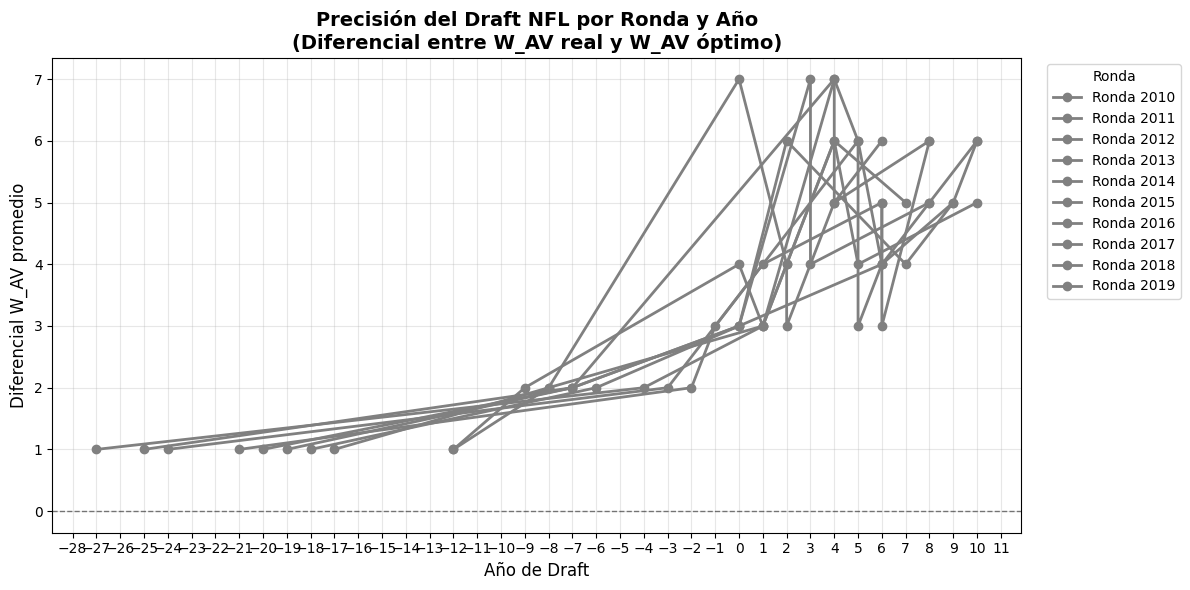

Gráfico guardado en data_raw/draft_precision.png


In [88]:
import matplotlib.pyplot as plt
import matplotlib.ticker as ticker

# Extraer datos de MongoDB
cursor = collection.aggregate([
    {"$match": {
        "draft_value.diferencial_wav": {"$ne": None},
        "posicion_grupo": {"$ne": None},
        "draft.temporada": {"$lte": 2019}
    }},
    {"$group": {
        "_id": {
            "temporada": "$draft.temporada",
            "ronda": "$draft.ronda"
        },
        "diferencial_promedio": {"$avg": "$draft_value.diferencial_wav"}
    }},
    {"$sort": {"_id.temporada": 1}}
])

# Convertir a DataFrame
df_viz = pd.json_normalize(list(cursor))
df_viz.columns = ['temporada', 'ronda', 'diferencial_promedio']
df_viz['temporada'] = df_viz['temporada'].astype(int)
df_viz['ronda'] = df_viz['ronda'].astype(int)

# Crear visualización
fig, ax = plt.subplots(figsize=(12, 6))

colores = {1: '#C8102E', 2: '#003F87', 3: '#00843D', 
           4: '#FF8200', 5: '#6F2C91', 6: '#888888', 7: '#000000'}

for ronda in sorted(df_viz['ronda'].unique()):
    datos_ronda = df_viz[df_viz['ronda'] == ronda].sort_values('temporada')
    ax.plot(datos_ronda['temporada'], 
            datos_ronda['diferencial_promedio'],
            marker='o', linewidth=2, markersize=6,
            color=colores.get(ronda, 'gray'),
            label=f'Ronda {ronda}')

# Línea de referencia en 0
ax.axhline(y=0, color='black', linestyle='--', linewidth=1, alpha=0.5)

ax.set_xlabel('Año de Draft', fontsize=12)
ax.set_ylabel('Diferencial W_AV promedio', fontsize=12)
ax.set_title('Precisión del Draft NFL por Ronda y Año\n(Diferencial entre W_AV real y W_AV óptimo)', 
             fontsize=14, fontweight='bold')
ax.legend(title='Ronda', bbox_to_anchor=(1.02, 1), loc='upper left')
ax.xaxis.set_major_locator(ticker.MultipleLocator(1))
ax.grid(True, alpha=0.3)

plt.tight_layout()
plt.savefig('data_raw/draft_precision.png', dpi=150, bbox_inches='tight')
plt.show()

print("Gráfico guardado en data_raw/draft_precision.png")

In [87]:
!pip install matplotlib --quiet

In [89]:
# Extraer datos de MongoDB
cursor = collection.aggregate([
    {"$match": {
        "draft_value.diferencial_wav": {"$ne": None},
        "posicion_grupo": {"$ne": None},
        "draft.temporada": {"$lte": 2019}
    }},
    {"$group": {
        "_id": {
            "temporada": "$draft.temporada",
            "ronda": "$draft.ronda"
        },
        "diferencial_promedio": {"$avg": "$draft_value.diferencial_wav"}
    }},
    {"$sort": {"_id.temporada": 1}}
])

# Convertir a DataFrame correctamente
datos = list(cursor)
df_viz = pd.DataFrame([{
    'temporada': d['_id']['temporada'],
    'ronda': d['_id']['ronda'],
    'diferencial_promedio': d['diferencial_promedio']
} for d in datos])

print("Primeras filas:")
print(df_viz.head(10))
print(f"\nRondas disponibles: {sorted(df_viz['ronda'].unique())}")
print(f"Temporadas: {sorted(df_viz['temporada'].unique())}")

Primeras filas:
   temporada  ronda  diferencial_promedio
0       2010      3              2.242424
1       2010      2             -8.593750
2       2010      5              4.657143
3       2010      7              0.000000
4       2010      6              8.406250
5       2010      1            -17.312500
6       2010      4              2.939394
7       2011      5              8.562500
8       2011      7              3.000000
9       2011      1            -20.062500

Rondas disponibles: [1, 2, 3, 4, 5, 6, 7]
Temporadas: [2010, 2011, 2012, 2013, 2014, 2015, 2016, 2017, 2018, 2019]


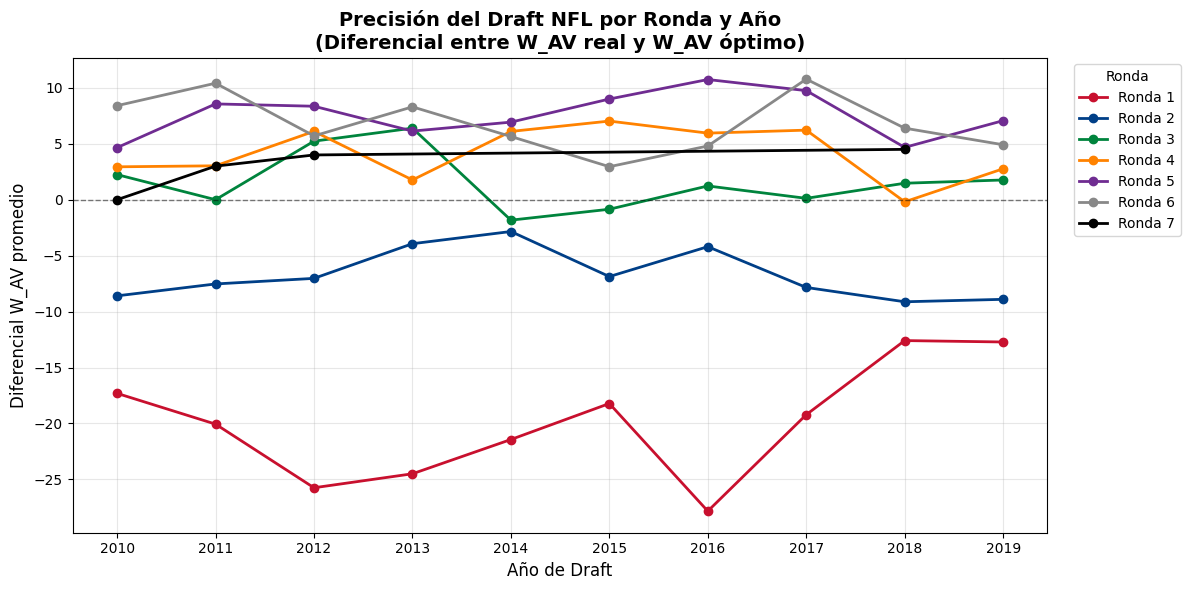

Gráfico guardado!


In [90]:
import matplotlib.pyplot as plt
import matplotlib.ticker as ticker

fig, ax = plt.subplots(figsize=(12, 6))

colores = {1: '#C8102E', 2: '#003F87', 3: '#00843D', 
           4: '#FF8200', 5: '#6F2C91', 6: '#888888', 7: '#000000'}

for ronda in sorted(df_viz['ronda'].unique()):
    datos_ronda = df_viz[df_viz['ronda'] == ronda].sort_values('temporada')
    ax.plot(datos_ronda['temporada'], 
            datos_ronda['diferencial_promedio'],
            marker='o', linewidth=2, markersize=6,
            color=colores.get(ronda, 'gray'),
            label=f'Ronda {ronda}')

# Línea de referencia en 0
ax.axhline(y=0, color='black', linestyle='--', linewidth=1, alpha=0.5)

ax.set_xlabel('Año de Draft', fontsize=12)
ax.set_ylabel('Diferencial W_AV promedio', fontsize=12)
ax.set_title('Precisión del Draft NFL por Ronda y Año\n(Diferencial entre W_AV real y W_AV óptimo)', 
             fontsize=14, fontweight='bold')
ax.legend(title='Ronda', bbox_to_anchor=(1.02, 1), loc='upper left')
ax.set_xticks(sorted(df_viz['temporada'].unique()))
ax.grid(True, alpha=0.3)

plt.tight_layout()
plt.savefig('data_raw/draft_precision.png', dpi=150, bbox_inches='tight')
plt.show()

print("Gráfico guardado!")

In [91]:
cursor = collection.find(
    {
        "draft_value.diferencial_wav": {"$ne": None},
        "posicion_grupo": {"$ne": None},
        "draft.temporada": {"$lte": 2019}
    },
    {
        "_id": 0,
        "nombre": 1,
        "draft.temporada": 1,
        "draft.ronda": 1,
        "draft_value.diferencia_pick": 1,
        "draft_value.diferencial_wav": 1
    }
)

datos = list(cursor)
df_scatter = pd.DataFrame([{
    'temporada': d['draft']['temporada'],
    'ronda': d['draft']['ronda'],
    'diferencia_pick': d['draft_value']['diferencia_pick'],
    'diferencial_wav': d['draft_value']['diferencial_wav']
} for d in datos])

print(f"Jugadores: {len(df_scatter)}")
print(df_scatter.head())

Jugadores: 1951
   temporada  ronda  diferencia_pick  diferencial_wav
0       2010      1              -36            -65.0
1       2010      1                0              0.0
2       2010      1              -11            -23.0
3       2010      1                3             20.0
4       2010      1              -25            -32.0


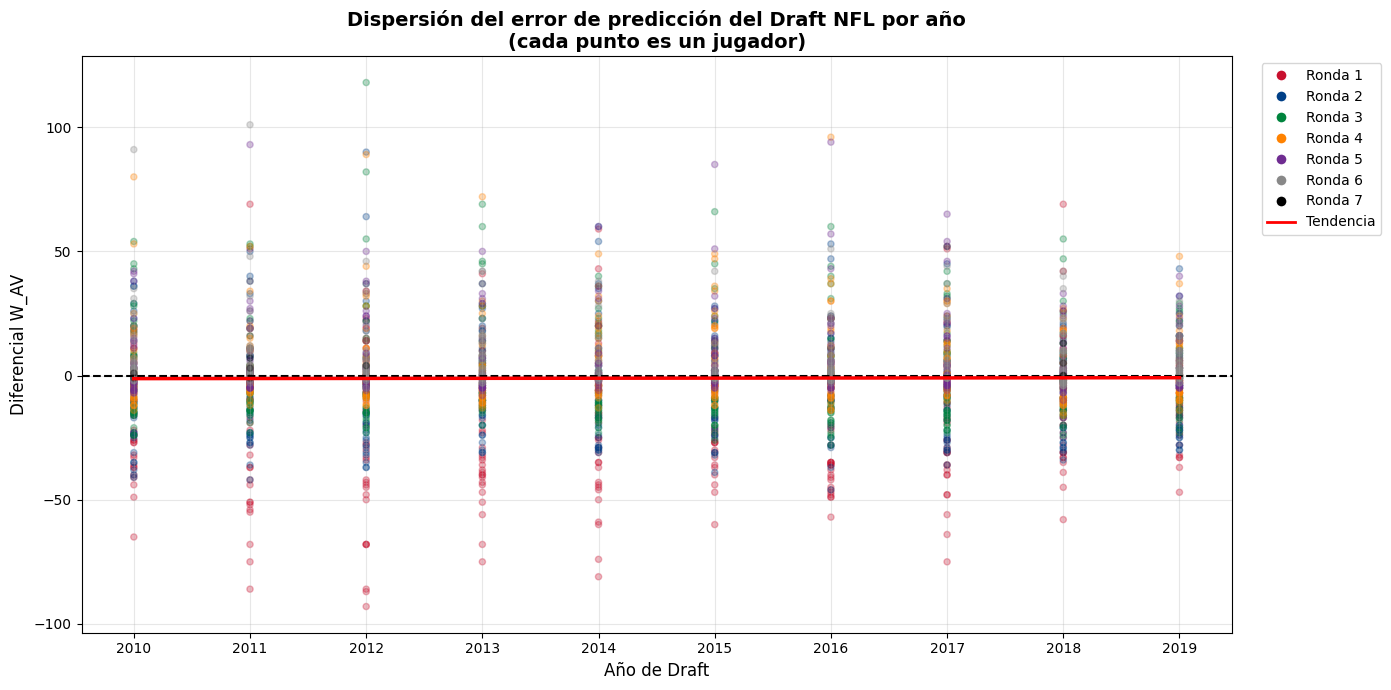

Gráfico guardado!


In [92]:
fig, ax = plt.subplots(figsize=(14, 7))

# Separar rondas altas y bajas para colorear
colores_ronda = df_scatter['ronda'].map({
    1: '#C8102E', 2: '#003F87', 3: '#00843D',
    4: '#FF8200', 5: '#6F2C91', 6: '#888888', 7: '#000000'
})

ax.scatter(
    df_scatter['temporada'],
    df_scatter['diferencial_wav'],
    c=colores_ronda,
    alpha=0.3,
    s=20
)

# Línea de referencia en 0
ax.axhline(y=0, color='black', linestyle='--', linewidth=1.5)

# Añadir línea de tendencia general
from numpy.polynomial import polynomial as P
x = df_scatter['temporada']
y = df_scatter['diferencial_wav']
coefs = P.polyfit(x, y, 1)
x_line = sorted(x.unique())
y_line = P.polyval(x_line, coefs)
ax.plot(x_line, y_line, color='red', linewidth=2.5, 
        linestyle='-', label='Tendencia general')

ax.set_xlabel('Año de Draft', fontsize=12)
ax.set_ylabel('Diferencial W_AV', fontsize=12)
ax.set_title('Dispersión del error de predicción del Draft NFL por año\n(cada punto es un jugador)', 
             fontsize=14, fontweight='bold')
ax.set_xticks(sorted(df_scatter['temporada'].unique()))

# Leyenda de rondas
from matplotlib.lines import Line2D
legend_elements = [
    Line2D([0], [0], marker='o', color='w', markerfacecolor=c, 
           markersize=8, label=f'Ronda {r}')
    for r, c in {1: '#C8102E', 2: '#003F87', 3: '#00843D',
                 4: '#FF8200', 5: '#6F2C91', 6: '#888888', 7: '#000000'}.items()
]
legend_elements.append(Line2D([0], [0], color='red', linewidth=2, label='Tendencia'))
ax.legend(handles=legend_elements, bbox_to_anchor=(1.02, 1), loc='upper left')

ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.savefig('data_raw/draft_dispersion.png', dpi=150, bbox_inches='tight')
plt.show()

print("Gráfico guardado!")

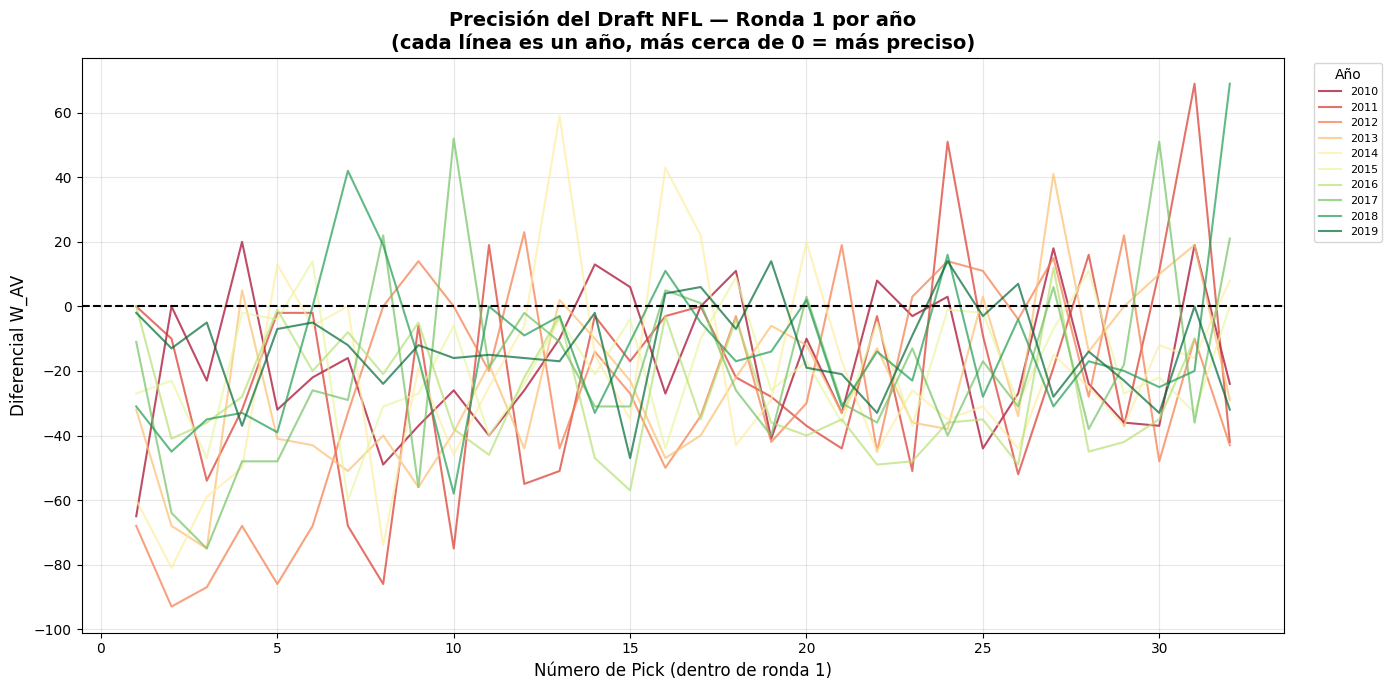

Gráfico guardado!


In [105]:
fig, ax = plt.subplots(figsize=(14, 7))

# Filtrar solo ronda 1
df_r1 = df_scatter[df_scatter['ronda'] == 1].copy()

# Añadir el pick number — necesitamos extraerlo de MongoDB
cursor = collection.find(
    {
        "draft.ronda": 1,
        "draft_value.diferencial_wav": {"$ne": None},
        "draft.temporada": {"$lte": 2019}
    },
    {
        "_id": 0,
        "draft.temporada": 1,
        "draft.pick": 1,
        "draft_value.diferencial_wav": 1
    }
)

datos_r1 = list(cursor)
df_r1 = pd.DataFrame([{
    'temporada': d['draft']['temporada'],
    'pick': d['draft']['pick'],
    'diferencial_wav': d['draft_value']['diferencial_wav']
} for d in datos_r1]).sort_values(['temporada', 'pick'])

# Colormap para los años
años = sorted(df_r1['temporada'].unique())
cmap = plt.cm.RdYlGn
colores_años = {año: cmap(i / (len(años)-1)) for i, año in enumerate(años)}

for año in años:
    datos_año = df_r1[df_r1['temporada'] == año].sort_values('pick')
    ax.plot(datos_año['pick'], 
            datos_año['diferencial_wav'],
            linewidth=1.5, alpha=0.7,
            color=colores_años[año],
            label=str(año))

# Línea de referencia en 0
ax.axhline(y=0, color='black', linestyle='--', linewidth=1.5)

ax.set_xlabel('Número de Pick (dentro de ronda 1)', fontsize=12)
ax.set_ylabel('Diferencial W_AV', fontsize=12)
ax.set_title('Precisión del Draft NFL — Ronda 1 por año\n(cada línea es un año, más cerca de 0 = más preciso)', 
             fontsize=14, fontweight='bold')
ax.legend(title='Año', bbox_to_anchor=(1.02, 1), loc='upper left', fontsize=8)
ax.grid(True, alpha=0.3)

plt.tight_layout()
plt.savefig('data_raw/draft_r1_precision.png', dpi=150, bbox_inches='tight')
plt.show()

print("Gráfico guardado!")

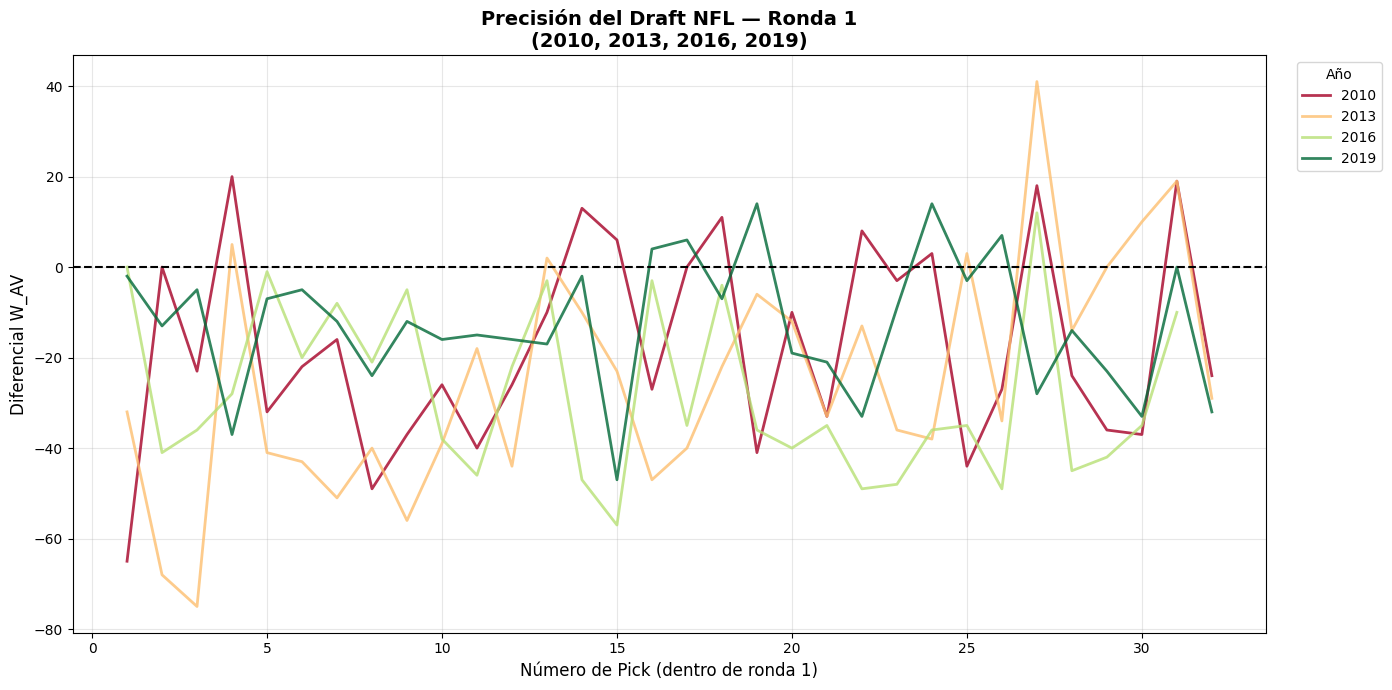

Gráfico guardado!


In [94]:
fig, ax = plt.subplots(figsize=(14, 7))

# Filtrar solo años cada 3
años_seleccionados = [2010, 2013, 2016, 2019]

df_filtrado = df_r1[df_r1['temporada'].isin(años_seleccionados)]

cmap = plt.cm.RdYlGn
colores_años = {año: cmap(i / (len(años_seleccionados)-1)) 
                for i, año in enumerate(años_seleccionados)}

for año in años_seleccionados:
    datos_año = df_filtrado[df_filtrado['temporada'] == año].sort_values('pick')
    ax.plot(datos_año['pick'], 
            datos_año['diferencial_wav'],
            linewidth=2, alpha=0.8,
            color=colores_años[año],
            label=str(año))

ax.axhline(y=0, color='black', linestyle='--', linewidth=1.5)

ax.set_xlabel('Número de Pick (dentro de ronda 1)', fontsize=12)
ax.set_ylabel('Diferencial W_AV', fontsize=12)
ax.set_title('Precisión del Draft NFL — Ronda 1\n(2010, 2013, 2016, 2019)', 
             fontsize=14, fontweight='bold')
ax.legend(title='Año', bbox_to_anchor=(1.02, 1), loc='upper left', fontsize=10)
ax.grid(True, alpha=0.3)

plt.tight_layout()
plt.savefig('data_raw/draft_r1_precision.png', dpi=150, bbox_inches='tight')
plt.show()

print("Gráfico guardado!")

<project folder> MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  bp = ax.boxplot(datos_por_año,


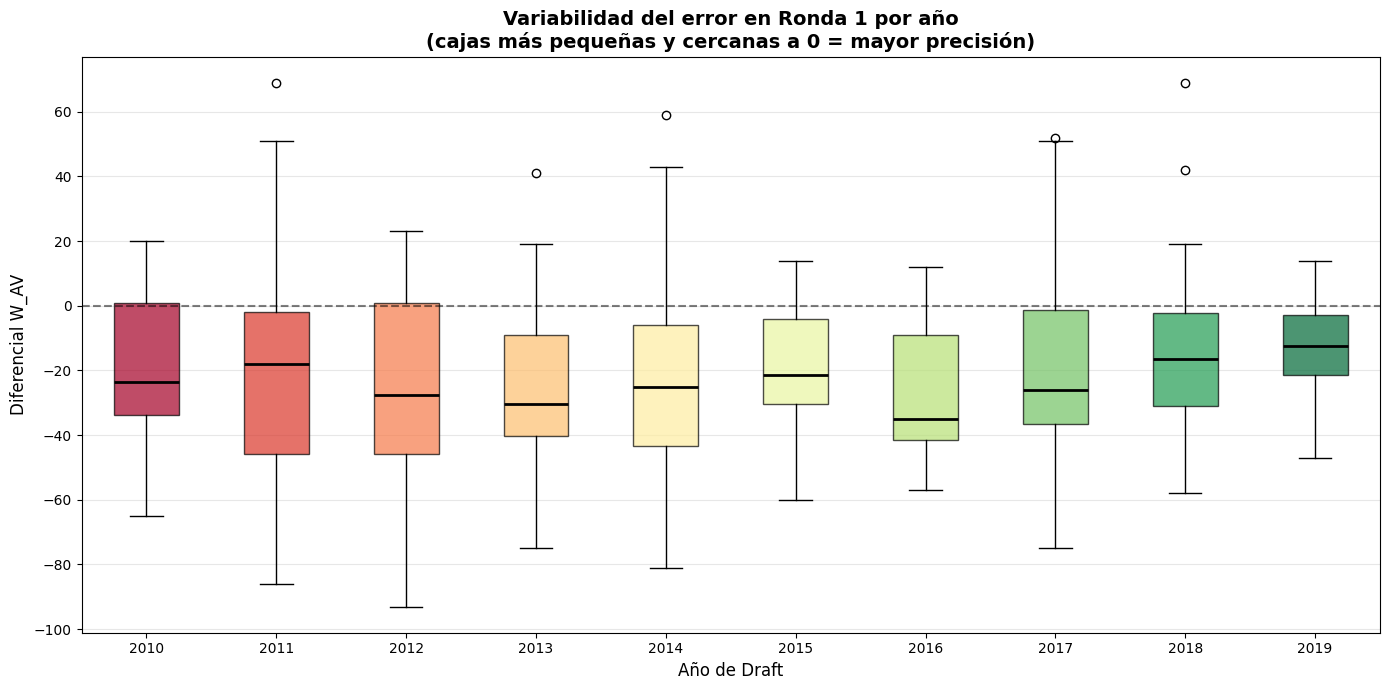

Gráfico guardado!


In [95]:
fig, ax = plt.subplots(figsize=(14, 7))

# Preparar datos por año en formato para boxplot
años = sorted(df_r1['temporada'].unique())
datos_por_año = [df_r1[df_r1['temporada'] == año]['diferencial_wav'].values 
                 for año in años]

bp = ax.boxplot(datos_por_año, 
                labels=años,
                patch_artist=True,
                medianprops=dict(color='black', linewidth=2))

# Colorear cajas de rojo a verde (antiguo a reciente)
cmap = plt.cm.RdYlGn
for i, patch in enumerate(bp['boxes']):
    patch.set_facecolor(cmap(i / (len(años)-1)))
    patch.set_alpha(0.7)

ax.axhline(y=0, color='black', linestyle='--', linewidth=1.5, alpha=0.5)

ax.set_xlabel('Año de Draft', fontsize=12)
ax.set_ylabel('Diferencial W_AV', fontsize=12)
ax.set_title('Variabilidad del error en Ronda 1 por año\n(cajas más pequeñas y cercanas a 0 = mayor precisión)', 
             fontsize=14, fontweight='bold')
ax.grid(True, alpha=0.3, axis='y')

plt.tight_layout()
plt.savefig('data_raw/draft_boxplot_r1.png', dpi=150, bbox_inches='tight')
plt.show()

print("Gráfico guardado!")

<project folder> MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  bp = ax.boxplot(datos_por_año,
<project folder> MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  bp = ax.boxplot(datos_por_año,
<project folder> MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  bp = ax.boxplot(datos_por_año,


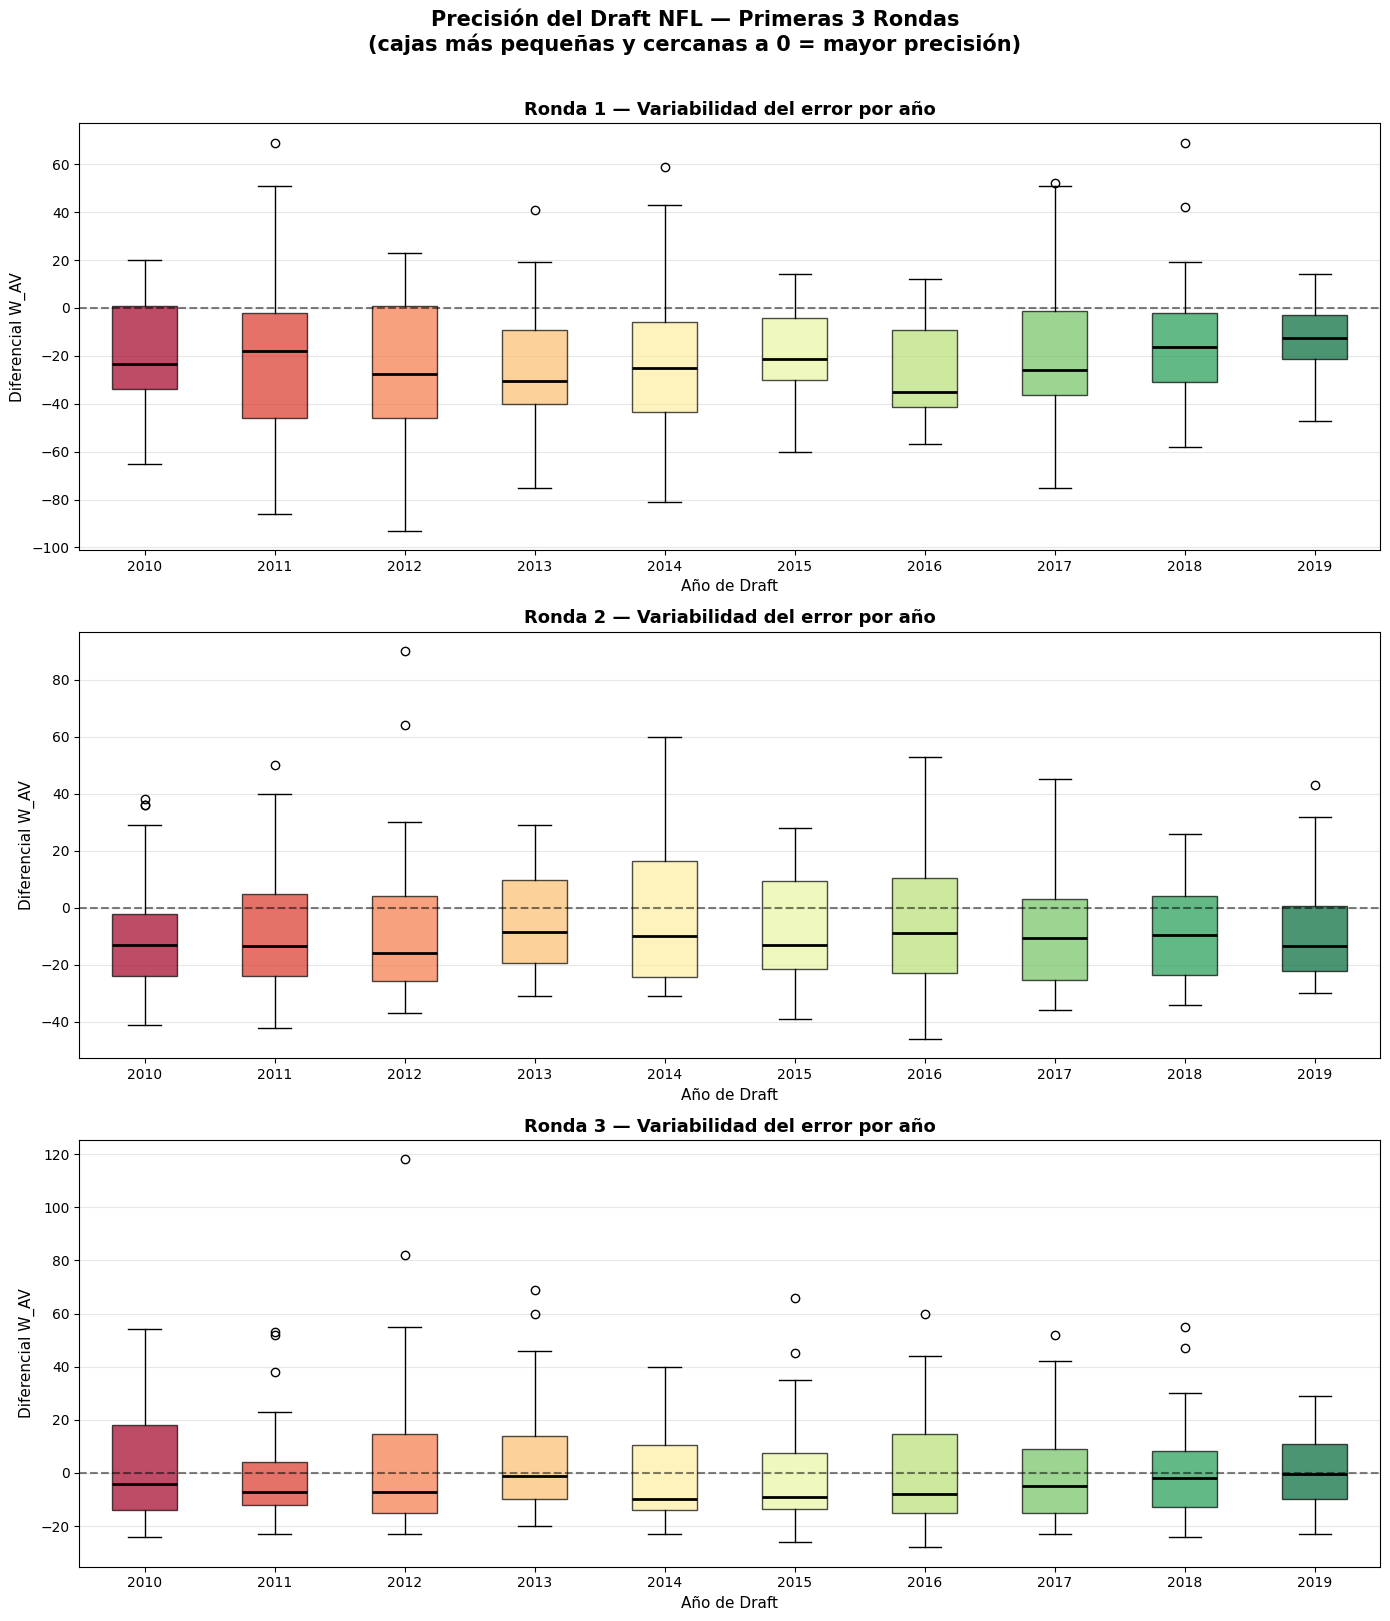

Gráfico guardado!


In [96]:
fig, axes = plt.subplots(3, 1, figsize=(14, 16))

rondas = [1, 2, 3]
titulos = ['Ronda 1', 'Ronda 2', 'Ronda 3']

for idx, (ronda, titulo) in enumerate(zip(rondas, titulos)):
    ax = axes[idx]
    
    # Filtrar por ronda
    df_ronda = df_r1[df_r1['temporada'].isin(años)] if ronda == 1 else \
               pd.DataFrame([{
                   'temporada': d['draft']['temporada'],
                   'pick': d['draft']['pick'],
                   'diferencial_wav': d['draft_value']['diferencial_wav']
               } for d in collection.find(
                   {"draft.ronda": ronda,
                    "draft_value.diferencial_wav": {"$ne": None},
                    "draft.temporada": {"$lte": 2019}},
                   {"_id": 0, "draft.temporada": 1, 
                    "draft.pick": 1, 
                    "draft_value.diferencial_wav": 1}
               )])
    
    años_ronda = sorted(df_ronda['temporada'].unique())
    datos_por_año = [df_ronda[df_ronda['temporada'] == año]['diferencial_wav'].values 
                     for año in años_ronda]
    
    bp = ax.boxplot(datos_por_año,
                    labels=años_ronda,
                    patch_artist=True,
                    medianprops=dict(color='black', linewidth=2))
    
    cmap = plt.cm.RdYlGn
    for i, patch in enumerate(bp['boxes']):
        patch.set_facecolor(cmap(i / (len(años_ronda)-1)))
        patch.set_alpha(0.7)
    
    ax.axhline(y=0, color='black', linestyle='--', linewidth=1.5, alpha=0.5)
    ax.set_xlabel('Año de Draft', fontsize=11)
    ax.set_ylabel('Diferencial W_AV', fontsize=11)
    ax.set_title(f'{titulo} — Variabilidad del error por año', fontsize=13, fontweight='bold')
    ax.grid(True, alpha=0.3, axis='y')

plt.suptitle('Precisión del Draft NFL — Primeras 3 Rondas\n(cajas más pequeñas y cercanas a 0 = mayor precisión)', 
             fontsize=15, fontweight='bold', y=1.01)

plt.tight_layout()
plt.savefig('data_raw/draft_boxplot_3rondas.png', dpi=150, bbox_inches='tight')
plt.show()

print("Gráfico guardado!")

<project folder> MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  bp = ax.boxplot(datos_por_año,


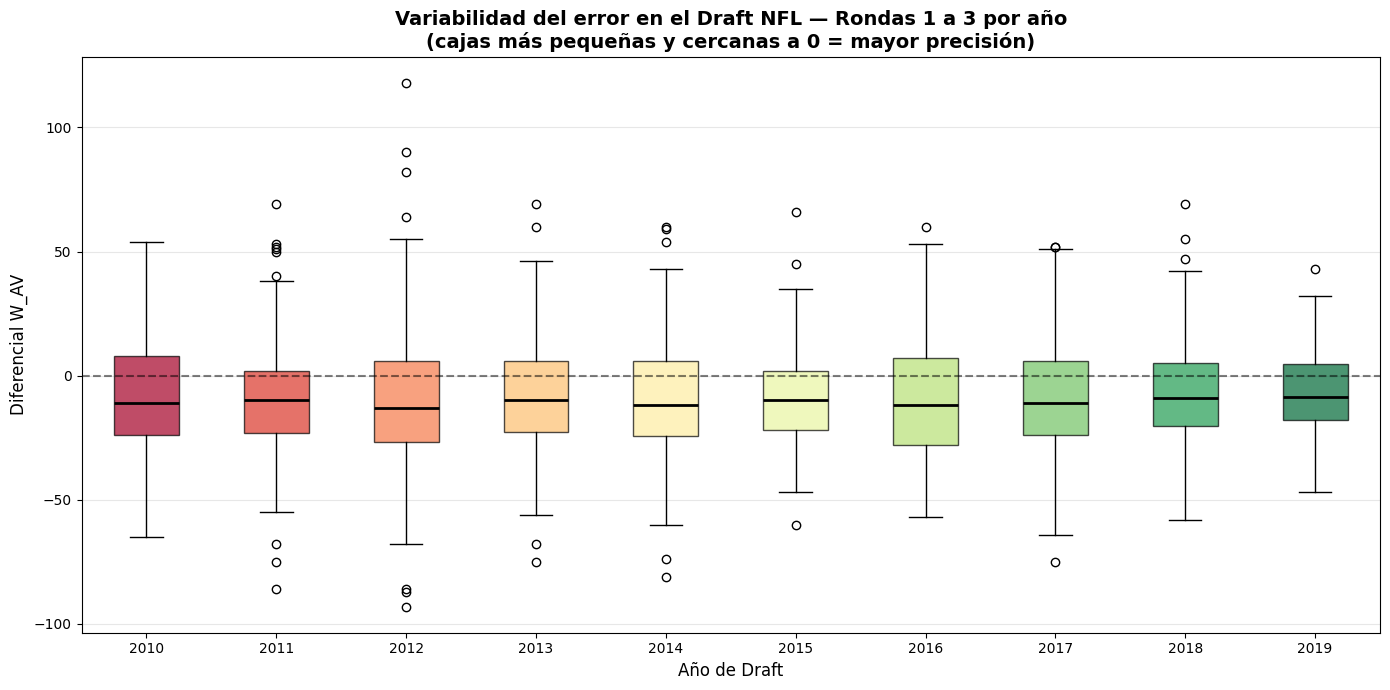

Gráfico guardado!


In [97]:
# Extraer datos de rondas 1, 2 y 3 combinadas
cursor = collection.find(
    {
        "draft.ronda": {"$lte": 3},
        "draft_value.diferencial_wav": {"$ne": None},
        "draft.temporada": {"$lte": 2019}
    },
    {
        "_id": 0,
        "draft.temporada": 1,
        "draft_value.diferencial_wav": 1
    }
)

df_3rondas = pd.DataFrame([{
    'temporada': d['draft']['temporada'],
    'diferencial_wav': d['draft_value']['diferencial_wav']
} for d in cursor])

años = sorted(df_3rondas['temporada'].unique())
datos_por_año = [df_3rondas[df_3rondas['temporada'] == año]['diferencial_wav'].values 
                 for año in años]

fig, ax = plt.subplots(figsize=(14, 7))

cmap = plt.cm.RdYlGn
bp = ax.boxplot(datos_por_año,
                labels=años,
                patch_artist=True,
                medianprops=dict(color='black', linewidth=2))

for i, patch in enumerate(bp['boxes']):
    patch.set_facecolor(cmap(i / (len(años)-1)))
    patch.set_alpha(0.7)

ax.axhline(y=0, color='black', linestyle='--', linewidth=1.5, alpha=0.5)
ax.set_xlabel('Año de Draft', fontsize=12)
ax.set_ylabel('Diferencial W_AV', fontsize=12)
ax.set_title('Variabilidad del error en el Draft NFL — Rondas 1 a 3 por año\n(cajas más pequeñas y cercanas a 0 = mayor precisión)',
             fontsize=14, fontweight='bold')
ax.grid(True, alpha=0.3, axis='y')

plt.tight_layout()
plt.savefig('data_raw/draft_boxplot_3rondas.png', dpi=150, bbox_inches='tight')
plt.show()

print("Gráfico guardado!")

In [98]:
posiciones = ['QB', 'RB', 'WR', 'EDGE']

cursor = collection.find(
    {
        "posicion_grupo": {"$in": posiciones},
        "nfl_career.w_av": {"$ne": None}
    },
    {
        "_id": 0,
        "nombre": 1,
        "posicion_grupo": 1,
        "nfl_career.w_av": 1,
        "combine.cuarenta": 1,
        "combine.vertical": 1,
        "combine.broad_jump": 1,
        "combine.bench": 1,
        "combine.cone": 1,
        "combine.shuttle": 1,
        "combine.altura_cm": 1,
        "combine.peso_kg": 1,
        "draft.ronda": 1
    }
)

df_corr = pd.json_normalize(list(cursor))

print(f"Jugadores extraídos: {len(df_corr)}")
print(f"\nColumnas: {df_corr.columns.tolist()}")
print(f"\nPor posición:")
print(df_corr['posicion_grupo'].value_counts())

Jugadores extraídos: 1126

Columnas: ['nombre', 'posicion_grupo', 'draft.ronda', 'nfl_career.w_av', 'combine.cuarenta', 'combine.bench', 'combine.vertical', 'combine.broad_jump', 'combine.cone', 'combine.shuttle', 'combine.altura_cm', 'combine.peso_kg']

Por posición:
WR      383
EDGE    347
RB      272
QB      124
Name: posicion_grupo, dtype: int64


In [99]:
variables_combine = [
    'combine.cuarenta', 'combine.bench', 'combine.vertical',
    'combine.broad_jump', 'combine.cone', 'combine.shuttle',
    'combine.altura_cm', 'combine.peso_kg'
]

# Calcular correlación de Pearson por posición
print("CORRELACIONES COMBINE vs W_AV POR POSICIÓN")
print("=" * 60)

resultados_corr = {}

for posicion in posiciones:
    df_pos = df_corr[df_corr['posicion_grupo'] == posicion].copy()
    
    correlaciones = {}
    for var in variables_combine:
        # Solo calcular si hay suficientes datos
        datos_validos = df_pos[['nfl_career.w_av', var]].dropna()
        if len(datos_validos) >= 20:
            corr = datos_validos['nfl_career.w_av'].corr(datos_validos[var])
            correlaciones[var.replace('combine.', '')] = round(corr, 3)
        else:
            correlaciones[var.replace('combine.', '')] = None
    
    resultados_corr[posicion] = correlaciones
    
    print(f"\n{posicion} (n={len(df_pos)}):")
    for var, corr in sorted(correlaciones.items(), 
                             key=lambda x: abs(x[1]) if x[1] else 0, 
                             reverse=True):
        if corr is not None:
            barra = "█" * int(abs(corr) * 20)
            signo = "+" if corr > 0 else "-"
            print(f"  {var:12} {signo}{abs(corr):.3f} {barra}")
        else:
            print(f"  {var:12} insuficientes datos")

CORRELACIONES COMBINE vs W_AV POR POSICIÓN

QB (n=124):
  cone         -0.209 ████
  broad_jump   +0.188 ███
  cuarenta     -0.176 ███
  peso_kg      -0.135 ██
  altura_cm    -0.116 ██
  shuttle      -0.045 
  vertical     +0.009 
  bench        insuficientes datos

RB (n=272):
  broad_jump   +0.196 ███
  cone         -0.142 ██
  cuarenta     -0.121 ██
  shuttle      -0.067 █
  vertical     +0.063 █
  bench        -0.032 
  altura_cm    +0.031 
  peso_kg      +0.019 

WR (n=383):
  shuttle      -0.080 █
  peso_kg      +0.068 █
  cone         -0.061 █
  vertical     +0.060 █
  altura_cm    +0.054 █
  cuarenta     -0.040 
  bench        +0.035 
  broad_jump   -0.005 

EDGE (n=347):
  cuarenta     -0.129 ██
  altura_cm    +0.126 ██
  shuttle      -0.125 ██
  cone         -0.114 ██
  vertical     +0.109 ██
  peso_kg      +0.101 ██
  bench        +0.087 █
  broad_jump   +0.066 █


In [100]:
cursor = collection.find(
    {
        "posicion_grupo": {"$in": posiciones},
        "nfl_career.w_av": {"$ne": None},
        "college_stats": {"$ne": []}
    },
    {
        "_id": 0,
        "nombre": 1,
        "posicion_grupo": 1,
        "nfl_career.w_av": 1,
        "college_stats": 1
    }
)

datos_college = list(cursor)
print(f"Jugadores con college stats: {len(datos_college)}")
print(f"\nEjemplo de college_stats de un jugador:")
print(datos_college[0]['nombre'])
print(datos_college[0]['college_stats'])

Jugadores con college stats: 874

Ejemplo de college_stats de un jugador:
Sam Bradford
[{'temporada': 2009, 'passing': {'ATT': 69, 'COMPLETIONS': 39, 'INT': 0, 'PCT': 0.565, 'TD': 2, 'YDS': 562, 'YPA': 8.1}, 'rushing': {'CAR': 4, 'LONG': 5, 'TD': 0, 'YDS': -18, 'YPC': -4.5}}]


In [101]:
def extraer_ultima_temporada(jugador):
    """
    Extrae las stats de la última temporada universitaria
    y las aplana en un diccionario simple.
    """
    college_stats = jugador.get('college_stats', [])
    if not college_stats:
        return None
    
    # Última temporada
    ultima = max(college_stats, key=lambda x: x['temporada'])
    
    resultado = {
        'nombre': jugador['nombre'],
        'posicion_grupo': jugador['posicion_grupo'],
        'w_av': jugador['nfl_career']['w_av']
    }
    
    # Aplanar todas las categorías de stats
    for categoria in ['passing', 'rushing', 'receiving', 'defensive']:
        if categoria in ultima:
            for stat, valor in ultima[categoria].items():
                resultado[f'{categoria}_{stat}'] = valor
    
    return resultado

# Construir DataFrame
registros = []
for jugador in datos_college:
    r = extraer_ultima_temporada(jugador)
    if r:
        registros.append(r)

df_college = pd.DataFrame(registros)

print(f"Jugadores con última temporada: {len(df_college)}")
print(f"\nColumnas disponibles:")
print(df_college.columns.tolist())

Jugadores con última temporada: 874

Columnas disponibles:
['nombre', 'posicion_grupo', 'w_av', 'passing_ATT', 'passing_COMPLETIONS', 'passing_INT', 'passing_PCT', 'passing_TD', 'passing_YDS', 'passing_YPA', 'rushing_CAR', 'rushing_LONG', 'rushing_TD', 'rushing_YDS', 'rushing_YPC', 'receiving_LONG', 'receiving_REC', 'receiving_TD', 'receiving_YDS', 'receiving_YPR', 'defensive_PD', 'defensive_QB HUR', 'defensive_SACKS', 'defensive_SOLO', 'defensive_TD', 'defensive_TFL', 'defensive_TOT']


In [102]:
# Variables relevantes por posición
vars_por_posicion = {
    'QB': ['passing_YDS', 'passing_TD', 'passing_INT', 'passing_PCT', 
           'passing_YPA', 'rushing_YDS', 'rushing_TD'],
    'RB': ['rushing_YDS', 'rushing_TD', 'rushing_YPC', 'rushing_CAR',
           'receiving_YDS', 'receiving_REC'],
    'WR': ['receiving_YDS', 'receiving_TD', 'receiving_YPR', 
           'receiving_REC', 'receiving_LONG'],
    'EDGE': ['defensive_SACKS', 'defensive_TFL', 'defensive_QB HUR',
             'defensive_TOT', 'defensive_SOLO']
}

print("CORRELACIONES COLLEGE STATS vs W_AV POR POSICIÓN")
print("=" * 60)

resultados_college = {}

for posicion in posiciones:
    df_pos = df_college[df_college['posicion_grupo'] == posicion].copy()
    variables = vars_por_posicion[posicion]
    
    correlaciones = {}
    for var in variables:
        if var in df_pos.columns:
            datos_validos = df_pos[['w_av', var]].dropna()
            if len(datos_validos) >= 20:
                corr = datos_validos['w_av'].corr(datos_validos[var])
                correlaciones[var] = round(corr, 3)
            else:
                correlaciones[var] = None
    
    resultados_college[posicion] = correlaciones
    
    print(f"\n{posicion} (n={len(df_pos)}):")
    for var, corr in sorted(correlaciones.items(),
                             key=lambda x: abs(x[1]) if x[1] else 0,
                             reverse=True):
        if corr is not None:
            barra = "█" * int(abs(corr) * 20)
            signo = "+" if corr > 0 else "-"
            print(f"  {var:25} {signo}{abs(corr):.3f} {barra}")
        else:
            print(f"  {var:25} insuficientes datos")

CORRELACIONES COLLEGE STATS vs W_AV POR POSICIÓN

QB (n=117):
  rushing_YDS               +0.271 █████
  passing_TD                +0.227 ████
  rushing_TD                +0.213 ████
  passing_PCT               +0.181 ███
  passing_YPA               +0.178 ███
  passing_YDS               +0.154 ███
  passing_INT               +0.011 

RB (n=250):
  rushing_TD                +0.308 ██████
  receiving_YDS             +0.291 █████
  rushing_YDS               +0.286 █████
  receiving_REC             +0.237 ████
  rushing_CAR               +0.221 ████
  rushing_YPC               +0.207 ████

WR (n=353):
  receiving_YDS             +0.214 ████
  receiving_TD              +0.214 ████
  receiving_REC             +0.205 ████
  receiving_LONG            +0.099 █
  receiving_YPR             +0.044 

EDGE (n=154):
  defensive_TOT             +0.182 ███
  defensive_TFL             +0.172 ███
  defensive_SOLO            +0.165 ███
  defensive_SACKS           +0.146 ██
  defensive_QB HUR          +0.

In [ ]:
!pip install scikit-learn --quiet

In [106]:
from sklearn.linear_model import LinearRegression
from sklearn.metrics import r2_score
from sklearn.preprocessing import StandardScaler
import numpy as np

# Variables por posición — combinando combine y college
vars_modelo = {
    'QB': {
        'combine': ['combine.cuarenta', 'combine.cone', 'combine.vertical'],
        'college': ['passing_TD', 'passing_YDS', 'passing_PCT', 
                   'passing_YPA', 'rushing_YDS', 'rushing_TD']
    },
    'RB': {
        'combine': ['combine.cuarenta', 'combine.broad_jump', 'combine.vertical'],
        'college': ['rushing_YDS', 'rushing_TD', 'rushing_YPC',
                   'receiving_YDS', 'receiving_REC']
    },
    'WR': {
        'combine': ['combine.cuarenta', 'combine.vertical', 'combine.broad_jump'],
        'college': ['receiving_YDS', 'receiving_TD', 'receiving_REC', 'receiving_YPR']
    },
    'EDGE': {
        'combine': ['combine.cuarenta', 'combine.bench', 'combine.cone'],
        'college': ['defensive_SACKS', 'defensive_TFL', 
                   'defensive_QB HUR', 'defensive_TOT']
    }
}

print("REGRESIÓN MÚLTIPLE — R² POR POSICIÓN")
print("=" * 60)

resultados_regresion = {}

for posicion in posiciones:
    print(f"\n{posicion}:")
    
    vars_c = vars_modelo[posicion]['combine']
    vars_col = vars_modelo[posicion]['college']
    
    # Cruzar df_corr y df_college por nombre
    df_pos_combine = df_corr[df_corr['posicion_grupo'] == posicion][
        ['nombre', 'nfl_career.w_av'] + vars_c
    ].copy()
    
    df_pos_college = df_college[df_college['posicion_grupo'] == posicion][
        ['nombre'] + [v for v in vars_col if v in df_college.columns]
    ].copy()
    
    # Merge por nombre
    df_merged = pd.merge(df_pos_combine, df_pos_college, on='nombre', how='inner')
    
    todas_vars = vars_c + [v for v in vars_col if v in df_merged.columns]
    
    # Eliminar filas con nulos
    df_clean = df_merged[['nfl_career.w_av'] + todas_vars].dropna()
    
    if len(df_clean) < 20:
        print(f"  Insuficientes datos: {len(df_clean)}")
        continue
    
    X = df_clean[todas_vars]
    y = df_clean['nfl_career.w_av']
    
    # Escalar variables
    scaler = StandardScaler()
    X_scaled = scaler.fit_transform(X)
    
    # Modelo solo combine
    X_combine = df_clean[vars_c].values
    X_combine_scaled = StandardScaler().fit_transform(X_combine)
    modelo_combine = LinearRegression().fit(X_combine_scaled, y)
    r2_combine = r2_score(y, modelo_combine.predict(X_combine_scaled))
    
    # Modelo solo college
    vars_col_disponibles = [v for v in vars_col if v in df_merged.columns]
    X_college = df_clean[vars_col_disponibles].values
    X_college_scaled = StandardScaler().fit_transform(X_college)
    modelo_college = LinearRegression().fit(X_college_scaled, y)
    r2_college = r2_score(y, modelo_college.predict(X_college_scaled))
    
    # Modelo combinado
    modelo_completo = LinearRegression().fit(X_scaled, y)
    r2_completo = r2_score(y, modelo_completo.predict(X_scaled))
    
    print(f"  Solo combine:          R² = {r2_combine:.3f} ({r2_combine*100:.1f}%)")
    print(f"  Solo college stats:    R² = {r2_college:.3f} ({r2_college*100:.1f}%)")
    print(f"  Combine + college:     R² = {r2_completo:.3f} ({r2_completo*100:.1f}%)")
    print(f"  Jugadores en modelo:   n  = {len(df_clean)}")
    
    resultados_regresion[posicion] = {
        'r2_combine': r2_combine,
        'r2_college': r2_college,
        'r2_completo': r2_completo,
        'n': len(df_clean)
    }

REGRESIÓN MÚLTIPLE — R² POR POSICIÓN

QB:
  Solo combine:          R² = 0.109 (10.9%)
  Solo college stats:    R² = 0.074 (7.4%)
  Combine + college:     R² = 0.170 (17.0%)
  Jugadores en modelo:   n  = 74

RB:
  Solo combine:          R² = 0.053 (5.3%)
  Solo college stats:    R² = 0.129 (12.9%)
  Combine + college:     R² = 0.164 (16.4%)
  Jugadores en modelo:   n  = 181

WR:
  Solo combine:          R² = 0.010 (1.0%)
  Solo college stats:    R² = 0.082 (8.2%)
  Combine + college:     R² = 0.096 (9.6%)
  Jugadores en modelo:   n  = 270

EDGE:
  Solo combine:          R² = 0.041 (4.1%)
  Solo college stats:    R² = 0.066 (6.6%)
  Combine + college:     R² = 0.094 (9.4%)
  Jugadores en modelo:   n  = 54


In [108]:
import json
from bson import ObjectId

# Extraer todos los documentos de MongoDB
cursor = collection.find({})
documentos = list(cursor)

# Convertir ObjectId a string para que sea JSON serializable
def convertir_objectid(doc):
    if isinstance(doc, dict):
        return {k: convertir_objectid(v) for k, v in doc.items()}
    elif isinstance(doc, list):
        return [convertir_objectid(i) for i in doc]
    elif isinstance(doc, ObjectId):
        return str(doc)
    else:
        return doc

documentos_limpios = [convertir_objectid(doc) for doc in documentos]

# Guardar como JSON
with open('data_raw/nfl_players_final.json', 'w', encoding='utf-8') as f:
    json.dump(documentos_limpios, f, indent=2, ensure_ascii=False)

print(f"Exportados: {len(documentos_limpios)} documentos")

import os
size = os.path.getsize('data_raw/nfl_players_final.json')
print(f"Tamaño: {size / (1024*1024):.2f} MB")

Exportados: 3313 documentos
Tamaño: 4.32 MB
